# Modelado no supervisado de la actividad sísmica en Argentina

El objetivo de este análisis es identificar y caracterizar regiones con patrones similares de actividad sísmica, sin establecer previamente una clasificación de las zonas. Para ello, se utiliza una grilla espacial de 100 km y se construyen variables que resumen el comportamiento sísmico de cada celda, considerando la frecuencia, la persistencia, la magnitud y la profundidad de los eventos registrados.

Se aplicarán técnicas de aprendizaje no supervisado para agrupar las celdas según sus características. Se utilizará K-Means sobre las variables originales estandarizadas y se explorará una alternativa basada en Análisis de Componentes Principales (PCA), con el propósito de evaluar distintas estructuras de agrupamiento y comparar el nivel de diferenciación que aporta cada enfoque.

Finalmente, se analizarán los perfiles de los clusters, su estabilidad y distribución espacial, y se examinará la influencia del episodio de agosto de 2021 sobre los resultados. 

### 1. Configuración inicial del análisis


In [1]:
# ============================================================
# 1.1. IMPORTACIÓN DE LIBRERÍAS
# ============================================================

# Configuración del entorno
import os
os.environ["OMP_NUM_THREADS"] = "1"   # para los warnings

# Manipulación y análisis de datos
import numpy as np
import pandas as pd

# Análisis y manejo de información geográfica
import geopandas as gpd
from shapely.geometry import Polygon, box
from shapely.ops import transform

# Visualización de datos
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Preprocesamiento de datos
from sklearn.preprocessing import StandardScaler

# Modelado no supervisado: K-Means
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Evaluación de clustering
from sklearn import metrics
from sklearn.metrics import (
    silhouette_samples,
    silhouette_score,
    adjusted_rand_score,
    pairwise_distances
)

# Comparación de combinaciones
from itertools import combinations


from IPython.display import display



In [2]:
# ============================================================
# 1.2. DEFINICIÓN DE FUNCIONES AUXILIARES
# ============================================================

# 1.2.1. MAPA DE CALOR

def mapa_de_calor(tabla, titulo, fmt="{:.2f}", cmap="RdBu_r", centro=0):
    """Dibuja un DataFrame como mapa de calor con el valor en cada celda."""
    valores = tabla.to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(1.05 * tabla.shape[1] + 2.4, 0.42 * tabla.shape[0] + 1.4))
    limite = np.abs(valores).max() if centro == 0 else None
    ax.imshow(valores, cmap=cmap, aspect="auto",
              vmin=-limite if limite else None, vmax=limite if limite else None)
    for r in range(valores.shape[0]):
        for c in range(valores.shape[1]):
            ax.text(c, r, fmt.format(valores[r, c]), ha="center", va="center", fontsize=8)
    ax.set_xticks(range(tabla.shape[1]), tabla.columns, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(tabla.shape[0]), tabla.index, fontsize=8)
    ax.set_title(titulo, fontsize=10)
    fig.tight_layout()
    plt.show()


# 1.2.2. BIPLOTS DE PCA


def dibujar_biplot(
    Z, cargas, nombres_vars,
    pc_x=0, pc_y=1,
    titulo="Biplot de PCA",
    escala_flechas=8,
    ajustes_etiquetas=None
):
    fig, ax = plt.subplots(figsize=(8.5, 5.6))

    # Observaciones
    ax.scatter(
        Z[:, pc_x],
        Z[:, pc_y],
        s=45,
        color="#4C72B0",
        alpha=0.65
    )

    # Flechas y etiquetas de las variables
    for j, var in enumerate(nombres_vars):

        fx = cargas[pc_x, j] * escala_flechas
        fy = cargas[pc_y, j] * escala_flechas

        ax.annotate(
            "",
            xy=(fx, fy),
            xytext=(0, 0),
            arrowprops=dict(
                arrowstyle="->",
                lw=1.8,
                color="#C44E52"
            )
        )

        # Desplazamiento individual de las etiquetas
        dx, dy = (ajustes_etiquetas or {}).get(var, (0, 0))

        ax.text(
            fx * 1.08 + dx,
            fy * 1.08 + dy,
            var,
            color="#901A1E",
            fontsize=8.5,
            fontweight="bold",
            ha="center",
            va="center"
        )

    ax.axhline(0, color="#ccc", lw=0.8)
    ax.axvline(0, color="#ccc", lw=0.8)

    ax.set_xlabel(f"PC{pc_x + 1}")
    ax.set_ylabel(f"PC{pc_y + 1}")
    ax.set_title(titulo, fontsize=10)

    # Ajustar límites para incluir todas las flechas
    margen = 1.5

    ax.set_xlim(
        min(Z[:, pc_x].min(), -1),
        max(Z[:, pc_x].max(), 8) + margen
    )

    ax.set_ylim(
        min(Z[:, pc_y].min(), -8) - margen,
        max(Z[:, pc_y].max(), 8) + margen
    )

    fig.tight_layout()
    plt.show()



# 1.2.3. FUNCIÓN PARA RESUMIR LOS VALORES ARI

def resumir_estabilidad(valores_ari):

    return {
        "ARI_promedio": np.mean(valores_ari),
        "ARI_desvio": np.std(valores_ari),
        "ARI_minimo": np.min(valores_ari),
        "ARI_maximo": np.max(valores_ari)
    }

# 1.2.4. FUNCIÓN PARA EVALUAR DISTINTAS INICIALIZACIONES

def evaluar_inicializaciones(
    datos,
    k,
    mascara_activas,
    n_repeticiones=30,
    semilla=42
):

    predicciones = []

    for i in range(n_repeticiones):

        modelo = KMeans(
            n_clusters=k,
            n_init=10,
            random_state=semilla + i
        )

        etiquetas = modelo.fit_predict(datos)

        predicciones.append(etiquetas)

    # Comparaciones sobre todas las celdas
    ari_total = [
        adjusted_rand_score(predicciones[i], predicciones[j])
        for i, j in combinations(range(n_repeticiones), 2)
    ]

    # Comparaciones sobre celdas activas
    ari_activas = [
        adjusted_rand_score(
            predicciones[i][mascara_activas],
            predicciones[j][mascara_activas]
        )
        for i, j in combinations(range(n_repeticiones), 2)
    ]

    return {
        "Todas las celdas": resumir_estabilidad(ari_total),
        "Solo celdas activas": resumir_estabilidad(ari_activas)
    }


# 1.2.5. FUNCIÓN PARA EVALUAR DISTINTAS SUBMUESTRAS

def evaluar_submuestras(
    datos_base,
    k,
    mascara_activas,
    usar_pca=False,
    n_componentes=3,
    n_repeticiones=20,
    proporcion_muestra=0.80,
    semilla=42
):

    rng = np.random.default_rng(semilla)

    n_celdas = len(datos_base)
    n_muestra = int(n_celdas * proporcion_muestra)

    predicciones = []

    for i in range(n_repeticiones):

        # Seleccionar muestra de entrenamiento
        indices = rng.choice(
            n_celdas,
            size=n_muestra,
            replace=False
        )

        muestra = datos_base.iloc[indices]

        # Ajustar escalado únicamente con la muestra
        escalador = StandardScaler()

        muestra_escalada = escalador.fit_transform(muestra)

        datos_completos_escalados = escalador.transform(datos_base)

        # Aplicar PCA cuando corresponda
        if usar_pca:

            pca_muestra = PCA(
                n_components=n_componentes
            )

            muestra_modelo = pca_muestra.fit_transform(
                muestra_escalada
            )

            datos_completos_modelo = pca_muestra.transform(
                datos_completos_escalados
            )

        else:

            muestra_modelo = muestra_escalada
            datos_completos_modelo = datos_completos_escalados

        # Entrenar K-Means
        modelo = KMeans(
            n_clusters=k,
            n_init=10,
            random_state=semilla + i
        )

        modelo.fit(muestra_modelo)

        # Predecir las etiquetas para todas las celdas
        etiquetas = modelo.predict(datos_completos_modelo)

        predicciones.append(etiquetas)

    # Comparaciones sobre todas las celdas
    ari_total = [
        adjusted_rand_score(predicciones[i], predicciones[j])
        for i, j in combinations(range(n_repeticiones), 2)
    ]

    # Comparaciones sobre celdas activas
    ari_activas = [
        adjusted_rand_score(
            predicciones[i][mascara_activas],
            predicciones[j][mascara_activas]
        )
        for i, j in combinations(range(n_repeticiones), 2)
    ]

    return {
        "Todas las celdas": resumir_estabilidad(ari_total),
        "Solo celdas activas": resumir_estabilidad(ari_activas)
    }

### 2. Preparación del área de estudio

In [3]:

# ============================================================
# 2.1. Lectura de archivos geográficos (IGN)
# ============================================================


# Capas utilizadas para delimitar el área de estudio
ign_provincias = gpd.read_file(
    "C:/Users/cari_/OneDrive/Escritorio/YPF Ciencia de Datos + IA/Proyecto Final/proyecto_ypf/data/raw/geodata/provinciaPolygon.shp"
)

ign_plataforma = gpd.read_file(
    "C:/Users/cari_/OneDrive/Escritorio/YPF Ciencia de Datos + IA/Proyecto Final/proyecto_ypf/data/raw/geodata/plataforma_continentalPolygon.shp"
)

# Capas utilizadas como referencia geográfica en los mapas
ign_sudam = gpd.read_file(
    "C:/Users/cari_/OneDrive/Escritorio/YPF Ciencia de Datos + IA/Proyecto Final/proyecto_ypf/data/raw/geodata/referencias.shp"
)

ign_arg = gpd.read_file(
    "C:/Users/cari_/OneDrive/Escritorio/YPF Ciencia de Datos + IA/Proyecto Final/proyecto_ypf/data/raw/geodata/limites.shp"
)


In [4]:

# ============================================================
# 2.2. CONSTRUCCIÓN DEL ÁREA DE ESTUDIO
# ============================================================

# Definir el sector antártico argentino mediante un polígono aproximado

coordenadas_antartida = [
    (-74.0, -60.0),   # Esquina noroeste
    (-25.0, -60.0),   # Esquina noreste
    (-25.0, -89.9),   # Límite este del sector antártico
    (-74.0, -89.9),   # Límite oeste del sector antártico
    (-74.0, -60.0)    # Cierre del polígono
]

poligono_antartico = Polygon(coordenadas_antartida)

# Unificar las provincias, la plataforma continental y el sector antártico

poligono_nacional = (
    ign_provincias.union_all()
    .union(ign_plataforma.union_all())
    .union(poligono_antartico)
)

# Crear GeoDataFrame del área de estudio

area_estudio = gpd.GeoDataFrame(
    {"nombre": ["Área de estudio"]},
    geometry=[poligono_nacional],
    crs="EPSG:4326"
)


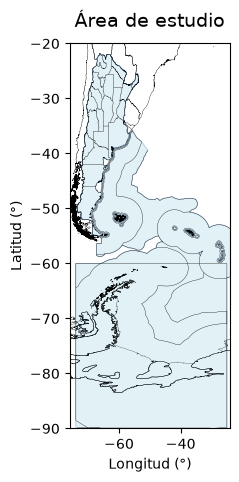

In [5]:

# ============================================================
# 2.3. VISUALIZACIÓN DEL ÁREA DE ESTUDIO
# ============================================================

fig, ax = plt.subplots(figsize=(7, 5))

# Referencia geográfica: Sudamérica
ign_sudam.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.25
)

# Área de estudio
area_estudio.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="steelblue",
    linewidth=0.7,
    alpha=0.35
)

# Límites de Argentina
ign_arg.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.25
)

# Configuración del mapa
ax.set_xlim(-76, -24)
ax.set_ylim(-90, -20)

ax.set_xlabel("Longitud (°)")
ax.set_ylabel("Latitud (°)")
ax.set_title(
    "Área de estudio",
    fontsize=14,
    pad=12
)

plt.show()


In [6]:

# ============================================================
# 2.4. CONSTRUCCIÓN DE LA GRILLA DE 100 KM
# ============================================================

# Corregir coordenadas en el límite polar
def corregir_latitud(x, y, z=None):
    y = np.clip(y, -89.9999, 90)

    if z is None:
        return x, y

    return x, y, z


area_estudio_corregida = area_estudio.copy()

area_estudio_corregida["geometry"] = (
    area_estudio_corregida.geometry.apply(
        lambda geom: transform(corregir_latitud, geom)
    )
)

# Definir proyección LAEA en metros
crs_proyectado = (
    "+proj=laea +lat_0=-50 +lon_0=-60 "
    "+datum=WGS84 +units=m +no_defs"
)

area_proyectada = area_estudio_corregida.to_crs(
    crs_proyectado
)

# Obtener límites del área proyectada
minx, miny, maxx, maxy = area_proyectada.total_bounds

print("Límites proyectados:", area_proyectada.total_bounds)
print("Geometría válida:", area_proyectada.geometry.is_valid.all())

# Definir tamaño de las celdas
tamano_celda_km = 100
tamano_celda = tamano_celda_km * 1000

# Generar coordenadas para construir la grilla
x_coords = np.arange(minx, maxx, tamano_celda)
y_coords = np.arange(miny, maxy, tamano_celda)

# Crear celdas cuadradas
celdas = []

for x in x_coords:
    for y in y_coords:
        celdas.append(
            box(
                x, y,
                x + tamano_celda,
                y + tamano_celda
            )
        )

# Construir GeoDataFrame de la grilla inicial
grilla = gpd.GeoDataFrame(
    {"geometry": celdas},
    crs=area_proyectada.crs
)

print("\nGrilla inicial creada.")
print("Cantidad de columnas:", len(x_coords))
print("Cantidad de filas:", len(y_coords))
print("Celdas candidatas:", len(grilla))


Límites proyectados: [-1013952.55708639 -4369194.98859597  2307667.07295116  3076079.53277883]
Geometría válida: True

Grilla inicial creada.
Cantidad de columnas: 34
Cantidad de filas: 75
Celdas candidatas: 2550


In [7]:

# ============================================================
# 2.5. RECORTE DE LA GRILLA AL ÁREA DE ESTUDIO
# ============================================================

# Separar el área de estudio en polígonos individuales
geometria_area = area_proyectada.geometry.iloc[0]

if hasattr(geometria_area, "geoms"):
    partes = list(geometria_area.geoms)
else:
    partes = [geometria_area]

partes_area = gpd.GeoDataFrame(
    {"geometry": partes},
    crs=area_proyectada.crs
)

# Crear índice espacial para optimizar las consultas
indice_area = partes_area.sindex

# Recortar las celdas que intersectan el área de estudio
geometrias_recortadas = []

for i, celda in enumerate(grilla.geometry):

    indices = indice_area.query(
        celda,
        predicate="intersects"
    )

    if len(indices) == 0:
        continue

    partes_candidatas = partes_area.geometry.iloc[indices]

    recorte = partes_candidatas.intersection(celda).union_all()

    if not recorte.is_empty and recorte.area > 0:
        geometrias_recortadas.append(recorte)

# Crear GeoDataFrame definitivo
grilla_recortada = gpd.GeoDataFrame(
    {"geometry": geometrias_recortadas},
    crs=grilla.crs
).reset_index(drop=True)

# Asignar identificadores únicos a cada celda
grilla_recortada["zona_id"] = [
    "Z" + str(i).zfill(5)
    for i in range(1, len(grilla_recortada) + 1)
]

# Verificar el resultado del recorte
print("Celdas iniciales:", len(grilla))
print("Celdas recortadas:", len(grilla_recortada))
print(
    "Geometrías válidas:",
    grilla_recortada.geometry.is_valid.all()
)


Celdas iniciales: 2550
Celdas recortadas: 1332
Geometrías válidas: True


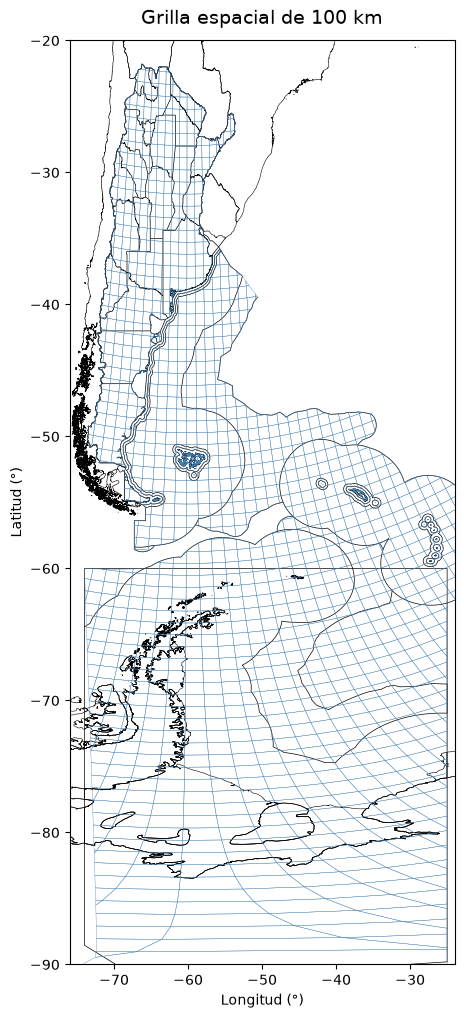

In [8]:

# ============================================================
# 2.6. VISUALIZACIÓN DE LA GRILLA DE 100 KM
# ============================================================

fig, ax = plt.subplots(figsize=(10, 12))

# Referencia geográfica: Sudamérica
ign_sudam.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.4
)

# Límites de Argentina
ign_arg.plot(
    ax=ax,
    color="black",
    linewidth=0.5
)

# Grilla recortada al área de estudio
grilla_recortada.to_crs("EPSG:4326").boundary.plot(
    ax=ax,
    color="steelblue",
    linewidth=0.25
)

# Configuración del mapa
ax.set_xlim(-76, -24)
ax.set_ylim(-90, -20)

ax.set_xlabel("Longitud (°)")
ax.set_ylabel("Latitud (°)")
ax.set_title(
    "Grilla espacial de 100 km",
    fontsize=14,
    pad=12
)

plt.show()


### 3. Carga y preparación del catálogo sísmico

In [9]:

# ============================================================
# 3. PREPARACIÓN DEL CATÁLOGO SÍSMICO
# ============================================================

# 3.1. CARGA DEL CATÁLOGO

ruta_sismos = (
    "C:/Users/cari_/OneDrive/Escritorio/"
    "YPF Ciencia de Datos + IA/Proyecto Final/"
    "proyecto_ypf/data/processed/sismos_argentina_limpio.csv"
)

sismos = pd.read_csv(ruta_sismos)

# Convertir la fecha a formato datetime
sismos["time"] = pd.to_datetime(
    sismos["time"],
    format="mixed",
    utc=True
)

print("Fechas no reconocidas:", sismos["time"].isna().sum())

# Verificar la carga del catálogo
print("Dimensiones del catálogo:", sismos.shape)

print("\nPrimeros registros:")
display(sismos.head(3))

print("\nColumnas disponibles:")
print(sismos.columns.tolist())


Fechas no reconocidas: 0
Dimensiones del catálogo: (6427, 20)

Primeros registros:


,time,latitude,longitude,depth,mag,magType,gap,dmin,rms,id,updated,place,horizontalError,depthError,magError,magNst,event_year,event_month,event_day,event_hour
0,2026-09-14 05:03:12.877000+00:00,-24.1313,-66.9986,189.041,4.4,mb,77.0,2.572,0.66,us7000than,2026-09-14 06:21:54.040000+00:00,"69 km W of San Antonio de los Cobres, Argentina",3.33,13.010,0.149,13.0,2026,9,14,5
1,2026-09-13 19:40:25.496000+00:00,-26.1509,-66.6119,10.000,4.7,mb,54.0,2.863,0.78,us7000th7y,2026-09-24 17:19:43.040000+00:00,"64 km W of Cafayate, Argentina",6.25,1.889,0.088,39.0,2026,9,13,19
2,2026-09-12 11:05:46.433000+00:00,-56.2951,-26.9013,102.352,4.9,mb,67.0,5.836,0.79,us7000tgyw,2026-09-23 07:20:17.040000+00:00,South Sandwich Islands region,12.33,7.797,0.106,28.0,2026,9,12,11



Columnas disponibles:
['time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'gap', 'dmin', 'rms', 'id', 'updated', 'place', 'horizontalError', 'depthError', 'magError', 'magNst', 'event_year', 'event_month', 'event_day', 'event_hour']


In [10]:

# ============================================================
# 3.2. SELECCIÓN DEL PERÍODO DE ANÁLISIS
# ============================================================

# Definir el período de análisis
fecha_inicio = pd.Timestamp("2016-10-01", tz="UTC")
fecha_fin = pd.Timestamp("2026-09-01", tz="UTC")

# Filtrar los eventos correspondientes al período
sismos_periodo = sismos.loc[
    (sismos["time"] >= fecha_inicio) &
    (sismos["time"] < fecha_fin)
].copy()

# Verificar los registros seleccionados
print("Registros originales:", len(sismos))
print("Registros del período seleccionado:", len(sismos_periodo))
print("Registros excluidos:", len(sismos) - len(sismos_periodo))

print("\nFecha del primer evento:")
print(sismos_periodo["time"].min())

print("\nFecha del último evento:")
print(sismos_periodo["time"].max())

print("\nValores faltantes en coordenadas:")
print(sismos_periodo[["latitude", "longitude"]].isna().sum())


Registros originales: 6427
Registros del período seleccionado: 6372
Registros excluidos: 55

Fecha del primer evento:
2016-10-01 08:05:13.730000+00:00

Fecha del último evento:
2026-08-31 21:45:56.991000+00:00

Valores faltantes en coordenadas:
latitude     0
longitude    0
dtype: int64


In [11]:

# ============================================================
# 3.3. CONVERSIÓN DE LOS SISMOS A GEOMETRÍAS
# ============================================================

# Crear puntos geográficos a partir de las coordenadas
sismos_geo = gpd.GeoDataFrame(
    sismos_periodo.copy(),
    geometry=gpd.points_from_xy(
        sismos_periodo["longitude"],
        sismos_periodo["latitude"]
    ),
    crs="EPSG:4326"
)

# Transformar al CRS proyectado de la grilla
sismos_geo = sismos_geo.to_crs(grilla_recortada.crs)

# Verificar la conversión
print("Cantidad de eventos:", len(sismos_geo))
print("CRS de los eventos:", sismos_geo.crs)
print("CRS de la grilla:", grilla_recortada.crs)
print(
    "Geometrías válidas:",
    sismos_geo.geometry.is_valid.all()
)


Cantidad de eventos: 6372
CRS de los eventos: +proj=laea +lat_0=-50 +lon_0=-60 +datum=WGS84 +units=m +no_defs +type=crs
CRS de la grilla: +proj=laea +lat_0=-50 +lon_0=-60 +datum=WGS84 +units=m +no_defs +type=crs
Geometrías válidas: True


In [12]:

# ============================================================
# 3.4. ASIGNACIÓN DE LOS SISMOS A LA GRILLA
# ============================================================

# Asignar cada evento a la celda que lo contiene
sismos_asignados = gpd.sjoin(
    sismos_geo,
    grilla_recortada[["zona_id", "geometry"]],
    how="left",
    predicate="within"
)

# Identificar eventos asignados y no asignados
asignados = sismos_asignados["zona_id"].notna()

# Verificar los resultados de la asignación
print("Total de sismos:", len(sismos_asignados))
print("Sismos asignados:", asignados.sum())
print("Sismos no asignados:", (~asignados).sum())

print(
    "Porcentaje asignado:",
    round(asignados.mean() * 100, 2),
    "%"
)


Total de sismos: 6372
Sismos asignados: 6372
Sismos no asignados: 0
Porcentaje asignado: 100.0 %


In [13]:

# ============================================================
# 3.5. CANTIDAD DE CELDAS ACTIVAS E INACTIVAS
# ============================================================

# Calcular la cantidad total de celdas
total_celdas = len(grilla_recortada)

# Identificar las celdas que recibieron al menos un sismo
celdas_activas = sismos_asignados["zona_id"].dropna().nunique()

# Calcular las celdas sin eventos
celdas_inactivas = total_celdas - celdas_activas

# Mostrar resultados
print("Cantidad total de celdas:", total_celdas)
print("Cantidad de celdas activas:", celdas_activas)
print("Cantidad de celdas inactivas (0 sismos):", celdas_inactivas)


Cantidad total de celdas: 1332
Cantidad de celdas activas: 204
Cantidad de celdas inactivas (0 sismos): 1128


In [14]:

# ============================================================
# 3.6. CONTEO MENSUAL DE SISMOS POR CELDA
# ============================================================

# Convertir las fechas al período mensual
sismos_asignados["mes"] = (
    sismos_asignados["time"]
    .dt.tz_localize(None)
    .dt.to_period("M")
)

# Contar eventos por celda y mes
conteos_mensuales = (
    sismos_asignados
    .dropna(subset=["zona_id"])
    .groupby(["zona_id", "mes"])
    .size()
    .reset_index(name="cantidad_sismos")
)

# Verificar los resultados
print("Registros de actividad mensual:", len(conteos_mensuales))
print("Celdas con actividad:", conteos_mensuales["zona_id"].nunique())
print("Meses registrados:", conteos_mensuales["mes"].nunique())

display(conteos_mensuales.head())


Registros de actividad mensual: 2734
Celdas con actividad: 204
Meses registrados: 119


,zona_id,mes,cantidad_sismos
0,Z00002,2023-11,1
1,Z00010,2024-05,1
2,Z00010,2026-03,1
3,Z00011,2024-01,1
4,Z00012,2020-01,1


In [15]:

# ============================================================
# 3.7. COMPLETAR LOS MESES SIN ACTIVIDAD
# ============================================================

# Definir todos los meses del período
meses = pd.period_range(
    start="2016-10",
    end="2026-08",
    freq="M"
)

# Identificar todas las celdas de la grilla
zonas = grilla_recortada["zona_id"].unique()

# Crear todas las combinaciones celda-mes
indice_completo = pd.MultiIndex.from_product(
    [zonas, meses],
    names=["zona_id", "mes"]
)

panel_mensual = (
    indice_completo
    .to_frame(index=False)
    .merge(
        conteos_mensuales,
        on=["zona_id", "mes"],
        how="left"
    )
)

# Completar meses sin actividad
panel_mensual["cantidad_sismos"] = (
    panel_mensual["cantidad_sismos"]
    .fillna(0)
    .astype(int)
)

# Verificar la construcción del panel
print("Cantidad total de celdas:", len(zonas))
print("Cantidad de meses:", len(meses))
print("Registros del panel:", len(panel_mensual))
print(
    "Registros con cero sismos:",
    (panel_mensual["cantidad_sismos"] == 0).sum()
)

display(panel_mensual.head(10))

print(
    "Combinaciones celda-mes únicas:",
    panel_mensual[["zona_id", "mes"]].drop_duplicates().shape[0]
)


Cantidad total de celdas: 1332
Cantidad de meses: 119
Registros del panel: 158508
Registros con cero sismos: 155774


,zona_id,mes,cantidad_sismos
0,Z00001,2016-10,0
1,Z00001,2016-11,0
2,Z00001,2016-12,0
3,Z00001,2017-01,0
4,Z00001,2017-02,0
5,Z00001,2017-03,0
6,Z00001,2017-04,0
7,Z00001,2017-05,0
8,Z00001,2017-06,0
9,Z00001,2017-07,0


Combinaciones celda-mes únicas: 158508


In [16]:

# ============================================================
# 3.8. CONSTRUCCIÓN DE VARIABLES DE ACTIVIDAD SÍSMICA
# ============================================================

# Calcular indicadores de actividad para cada celda
resumen_zonas = (
    panel_mensual
    .groupby("zona_id")
    .agg(
        cantidad_total=("cantidad_sismos", "sum"),
        meses_activos=("cantidad_sismos", lambda x: (x > 0).sum()),
        promedio_mensual=("cantidad_sismos", "mean"),
        maximo_mensual=("cantidad_sismos", "max"),
        desvio_mensual=("cantidad_sismos", "std")
    )
    .reset_index()
)

# Verificar los resultados
print("Cantidad de zonas:", len(resumen_zonas))

print("\nResumen estadístico:")
display(resumen_zonas.describe().round(2))

print("\nPrimeras filas:")
display(resumen_zonas.head())

print("\nValores faltantes:")
display(resumen_zonas.isna().sum())


Cantidad de zonas: 1332

Resumen estadístico:


,cantidad_total,meses_activos,promedio_mensual,maximo_mensual,desvio_mensual
count,1332.00,1332.00,1332.00,1332.00,1332.00
mean,4.78,2.05,0.04,0.81,0.10
std,36.14,10.27,0.30,6.27,0.63
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,0.00
50%,0.00,0.00,0.00,0.00,0.00
75%,0.00,0.00,0.00,0.00,0.00
max,793.00,118.00,6.66,147.00,14.08



Primeras filas:


,zona_id,cantidad_total,meses_activos,promedio_mensual,maximo_mensual,desvio_mensual
0,Z00001,0,0,0.000000,0,0.00000
1,Z00002,1,1,0.008403,1,0.09167
2,Z00003,0,0,0.000000,0,0.00000
3,Z00004,0,0,0.000000,0,0.00000
4,Z00005,0,0,0.000000,0,0.00000



Valores faltantes:


zona_id             0
cantidad_total      0
meses_activos       0
promedio_mensual    0
maximo_mensual      0
desvio_mensual      0
dtype: int64

In [17]:

# ============================================================
# 3.9. CARACTERÍSTICAS DE MAGNITUD Y PROFUNDIDAD
# ============================================================

# Calcular características de los eventos por celda
resumen_eventos = (
    sismos_asignados
    .dropna(subset=["zona_id"])
    .groupby("zona_id")
    .agg(
        magnitud_media=("mag", "mean"),
        magnitud_maxima=("mag", "max"),
        profundidad_media=("depth", "mean"),
        profundidad_maxima=("depth", "max")
    )
    .reset_index()
)

# Incorporar las variables al resumen de zonas
resumen_zonas = resumen_zonas.merge(
    resumen_eventos,
    on="zona_id",
    how="left"
)

# Verificar las variables disponibles
print("Variables disponibles:")
print(resumen_zonas.columns.tolist())

display(resumen_zonas.head())

print("\nCeldas sin eventos:")
print(
    "Magnitud media:",
    resumen_zonas["magnitud_media"].isna().sum()
)
print(
    "Profundidad media:",
    resumen_zonas["profundidad_media"].isna().sum()
)


Variables disponibles:
['zona_id', 'cantidad_total', 'meses_activos', 'promedio_mensual', 'maximo_mensual', 'desvio_mensual', 'magnitud_media', 'magnitud_maxima', 'profundidad_media', 'profundidad_maxima']


,zona_id,cantidad_total,meses_activos,promedio_mensual,maximo_mensual,desvio_mensual,magnitud_media,magnitud_maxima,profundidad_media,profundidad_maxima
0,Z00001,0,0,0.000000,0,0.00000,NaN,NaN,NaN,NaN
1,Z00002,1,1,0.008403,1,0.09167,4.2,4.2,10.0,10.0
2,Z00003,0,0,0.000000,0,0.00000,NaN,NaN,NaN,NaN
3,Z00004,0,0,0.000000,0,0.00000,NaN,NaN,NaN,NaN
4,Z00005,0,0,0.000000,0,0.00000,NaN,NaN,NaN,NaN



Celdas sin eventos:
Magnitud media: 1128
Profundidad media: 1128


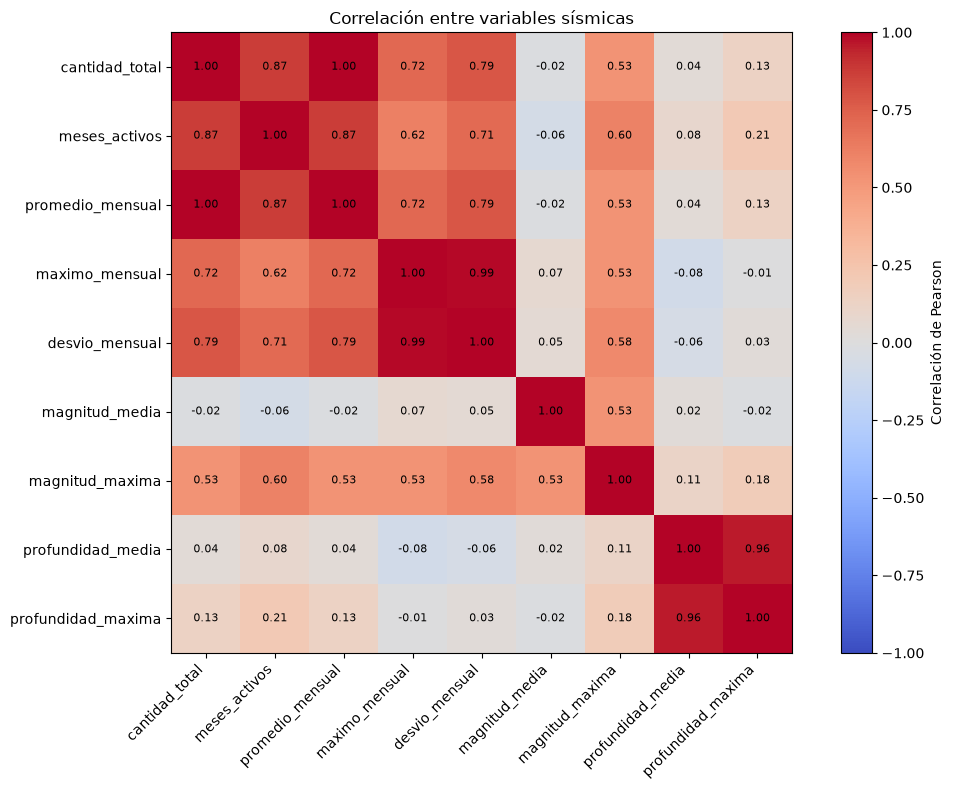

In [18]:

# ============================================================
# 3.10. CORRELACIÓN ENTRE VARIABLES
# ============================================================

# Seleccionar variables numéricas
variables = resumen_zonas.drop(columns="zona_id")

# Calcular correlaciones de Pearson
correlaciones = variables.corr(method="pearson")

# Visualizar la matriz de correlaciones
fig, ax = plt.subplots(figsize=(11, 8))

imagen = ax.imshow(
    correlaciones,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlaciones.columns)))
ax.set_yticks(range(len(correlaciones.columns)))

ax.set_xticklabels(
    correlaciones.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(correlaciones.columns)

# Mostrar los coeficientes en cada celda
for i in range(len(correlaciones)):
    for j in range(len(correlaciones)):
        valor = correlaciones.iloc[i, j]

        ax.text(
            j, i,
            f"{valor:.2f}" if pd.notna(valor) else "NA",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")

ax.set_title("Correlación entre variables sísmicas")
plt.tight_layout()
plt.show()


_Las correlaciones que involucran variables de magnitud y profundidad se calculan sobre las 204 celdas con eventos registrados, mientras que las correlaciones entre variables de actividad consideran las 1332 celdas de la grilla._

In [19]:

# ============================================================
# 3.11. SELECCIÓN Y REVISIÓN DE VARIABLES PARA EL CLUSTERING
# ============================================================

# Seleccionar variables para el clustering
variables_clustering = [
    "cantidad_total",
    "meses_activos",
    "maximo_mensual",
    "magnitud_media",
    "profundidad_media"
]

# Crear una copia con las variables seleccionadas
datos_clustering = resumen_zonas[variables_clustering].copy()

# Resumen estadístico
print("Resumen estadístico:")
display(datos_clustering.describe().round(2))

# Verificar valores faltantes
print("\nValores faltantes por variable:")
display(datos_clustering.isna().sum())

# Cantidad de celdas con información completa
print(
    "\nCeldas con información completa:",
    datos_clustering.notna().all(axis=1).sum()
)


Resumen estadístico:


,cantidad_total,meses_activos,maximo_mensual,magnitud_media,profundidad_media
count,1332.00,1332.00,1332.00,204.00,204.00
mean,4.78,2.05,0.81,4.61,77.56
std,36.14,10.27,6.27,0.36,128.97
min,0.00,0.00,0.00,3.00,9.35
25%,0.00,0.00,0.00,4.41,10.00
50%,0.00,0.00,0.00,4.58,13.08
75%,0.00,0.00,0.00,4.75,104.73
max,793.00,118.00,147.00,6.80,626.01



Valores faltantes por variable:


cantidad_total          0
meses_activos           0
maximo_mensual          0
magnitud_media       1128
profundidad_media    1128
dtype: int64


Celdas con información completa: 204


### 4. Preparación de los datos para el análisis de clustering

_En las celdas sin eventos sísmicos, las variables de magnitud media y profundidad media no tienen valores definidos. Para conservar todas las celdas en el análisis, estos valores faltantes se reemplazan por cero. En este contexto, el cero representa ausencia de registros sísmicos y no una medición observada de magnitud o profundidad._

In [20]:

# ============================================================
# 4.1. PREPARACIÓN Y ESCALADO DE VARIABLES
# ============================================================

# Representar con cero la ausencia de actividad sísmica
datos_clustering = datos_clustering.fillna(0)

# Estandarizar las variables
scaler = StandardScaler()

datos_escalados = pd.DataFrame(
    scaler.fit_transform(datos_clustering),
    columns=datos_clustering.columns,
    index=datos_clustering.index
)

# Verificar los resultados del escalado
print("Dimensiones de los datos escalados:", datos_escalados.shape)

print("\nMedia de las variables:")
print(datos_escalados.mean().round(3))

print("\nDesvío estándar de las variables:")
print(datos_escalados.std().round(3))

print("\nValores faltantes:")
print(datos_escalados.isna().sum().sum())

display(datos_escalados.head())


Dimensiones de los datos escalados: (1332, 5)

Media de las variables:
cantidad_total      -0.0
meses_activos       -0.0
maximo_mensual       0.0
magnitud_media      -0.0
profundidad_media    0.0
dtype: float64

Desvío estándar de las variables:
cantidad_total       1.0
meses_activos        1.0
maximo_mensual       1.0
magnitud_media       1.0
profundidad_media    1.0
dtype: float64

Valores faltantes:
0


,cantidad_total,meses_activos,maximo_mensual,magnitud_media,profundidad_media
0,-0.132425,-0.199951,-0.129196,-0.423752,-0.206302
1,-0.104743,-0.102535,0.030293,2.097827,-0.032619
2,-0.132425,-0.199951,-0.129196,-0.423752,-0.206302
3,-0.132425,-0.199951,-0.129196,-0.423752,-0.206302
4,-0.132425,-0.199951,-0.129196,-0.423752,-0.206302


_Se aplica el Análisis de Componentes Principales (PCA) como técnica exploratoria de reducción de dimensionalidad, con el objetivo de estudiar las relaciones entre las variables seleccionadas para el clustering y evaluar cuánta información puede resumirse en un número menor de componentes._

In [21]:
# ============================================================
# 4.2. ANÁLISIS DE COMPONENTES PRINCIPALES (PCA)
# ============================================================

# 4.2.1. Ajuste del PCA y varianza explicada


# Ajustar PCA sobre las variables estandarizadas
pca = PCA()
componentes = pca.fit_transform(datos_escalados)

# Varianza explicada por cada componente
varianza_explicada = pca.explained_variance_ratio_

# Resumen de varianza explicada
resumen_pca = pd.DataFrame({
    "componente": [f"PC{i+1}" for i in range(len(varianza_explicada))],
    "varianza_explicada": varianza_explicada,
    "varianza_acumulada": varianza_explicada.cumsum()
})

display(resumen_pca.round(4))




,componente,varianza_explicada,varianza_acumulada
0,PC1,0.5665,0.5665
1,PC2,0.2379,0.8044
2,PC3,0.1007,0.9051
3,PC4,0.0757,0.9807
4,PC5,0.0193,1.0000


,PC1,PC2,PC3,PC4,PC5
cantidad_total,0.5299,-0.2958,-0.2518,-0.2231,0.7201
meses_activos,0.5449,-0.1147,-0.1648,-0.4829,-0.6554
maximo_mensual,0.4646,-0.3428,0.2008,0.7722,-0.1732
magnitud_media,0.3737,0.5168,0.7399,-0.1546,0.1481
profundidad_media,0.2584,0.7175,-0.5672,0.3111,0.0027


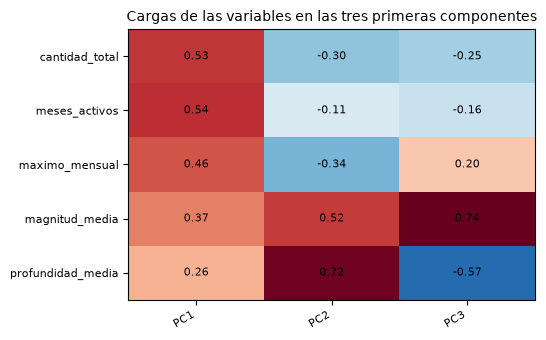

In [22]:
# 4.2.2. Cargas de las variables 

cargas_pca = pd.DataFrame(
    pca.components_.T,
    index=datos_escalados.columns,
    columns=[f"PC{i+1}" for i in range(len(datos_escalados.columns))]
)

display(cargas_pca.round(4))

mapa_de_calor(
    cargas_pca[["PC1", "PC2", "PC3"]],
    titulo="Cargas de las variables en las tres primeras componentes"
)

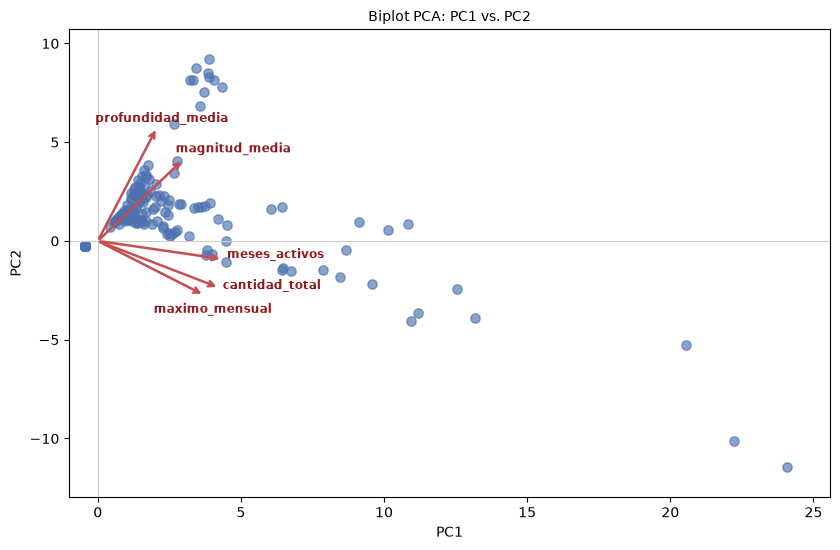

In [23]:
# 4.2.3. Visualización de las componentes

dibujar_biplot(
    componentes,
    pca.components_,
    datos_escalados.columns,
    pc_x=0,
    pc_y=1,
    titulo="Biplot PCA: PC1 vs. PC2",
    ajustes_etiquetas={
        "cantidad_total": (1.5, 0.3),
        "meses_activos": (1.5, 0.3),
        "magnitud_media": (1.5, 0.2),
        "maximo_mensual": (0, -0.5)

    }
)

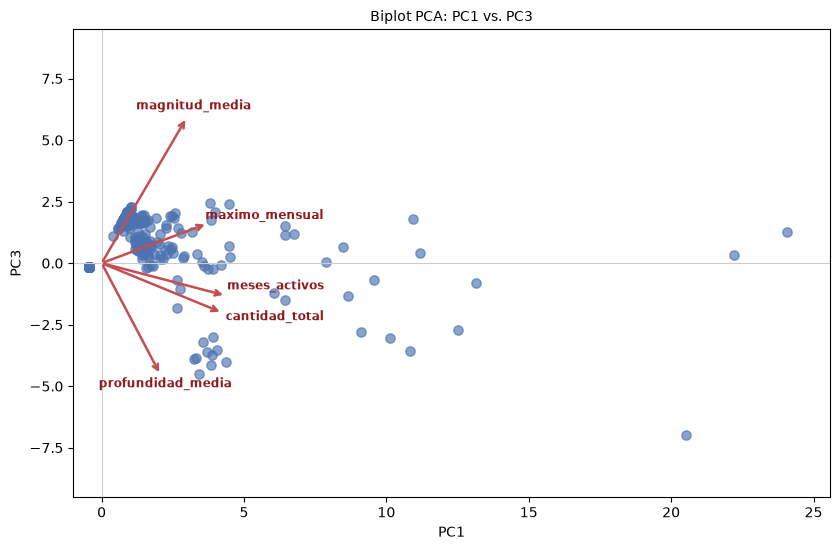

In [24]:

dibujar_biplot(
    componentes,
    pca.components_,
    datos_escalados.columns,
    pc_x=0,
    pc_y=2,
    titulo="Biplot PCA: PC1 vs. PC3",
    ajustes_etiquetas={
        "cantidad_total": (1.5, 0),
        "meses_activos": (1.4, 0.5),
        "maximo_mensual": (1.7, 0.2)

    }
)

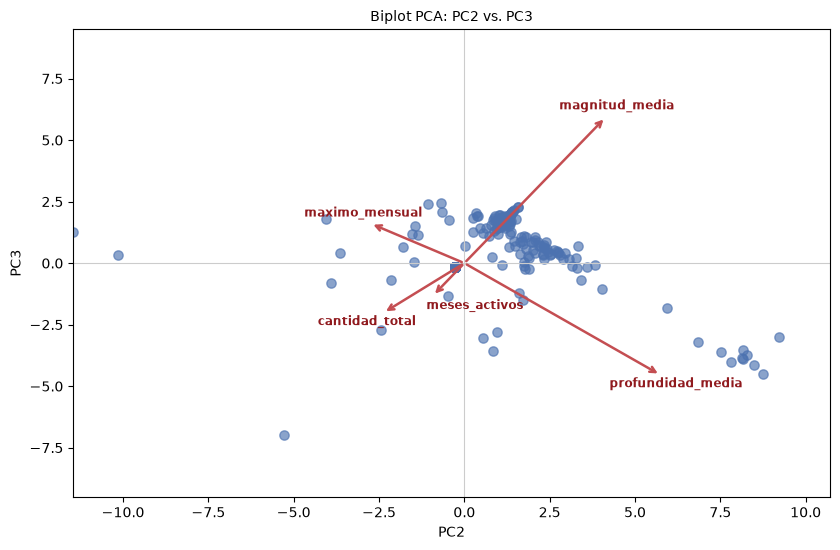

In [25]:

dibujar_biplot(
    componentes,
    pca.components_,
    datos_escalados.columns,
    pc_x=1,
    pc_y=2,
    titulo="Biplot PCA: PC2 vs. PC3",
    ajustes_etiquetas={
        "cantidad_total": (-0.3, -0.2),
        "meses_activos": (1.3, -0.3),
        "maximo_mensual": (0, 0.3)

    }
)

#### _Interpretación de las componentes principales_


Las tres primeras componentes explican el 90,5 % de la variabilidad total:
- PC1 (56,6 %): representa principalmente la intensidad y persistencia de la actividad sísmica, asociada a la cantidad de eventos, los meses activos y el máximo mensual.
- PC2 (23,7 %): se relaciona principalmente con la profundidad y magnitud media de los eventos.
- PC3 (10,0 %): expresa un contraste entre la magnitud media y la profundidad media.
En conjunto, permiten resumir las cinco variables originales en tres dimensiones.

In [26]:
# 4.2.4. Construcción del conjunto de datos PCA


# Seleccionar las tres primeras componentes
datos_pca = pd.DataFrame(
    componentes[:, :3],
    columns=["PC1", "PC2", "PC3"],
    index=datos_escalados.index
)

print("Dimensiones de los datos:", datos_pca.shape)
display(datos_pca.head())

Dimensiones de los datos: (1332, 3)


,PC1,PC2,PC3
0,-0.450826,-0.260602,-0.156151
1,0.678299,1.093064,1.620005
2,-0.450826,-0.260602,-0.156151
3,-0.450826,-0.260602,-0.156151
4,-0.450826,-0.260602,-0.156151


### 5. Diagnóstico de modelos de clustering

In [27]:

# ============================================================
# 5.1. EVALUACIÓN DE K-MEANS PARA DISTINTOS VALORES DE K
# ============================================================

filas = []

modelos_kmeans = {}

for k in range(2, 9):

    modelo = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    etiquetas = modelo.fit_predict(datos_escalados)

    modelos_kmeans[k] = modelo

    filas.append({
        "K": k,
        "inercia": modelo.inertia_,
        "silueta": metrics.silhouette_score(
            datos_escalados, etiquetas
        ),
        "calinski_harabasz": metrics.calinski_harabasz_score(
            datos_escalados, etiquetas
        ),
        "davies_bouldin": metrics.davies_bouldin_score(
            datos_escalados, etiquetas
        )
    })

tabla_k_s = pd.DataFrame(filas).set_index("K")

display(tabla_k_s.round(3))


# PORCENTAJE DE CAMBIO ENTRE VALORES CONSECUTIVOS DE K

cambios_k = pd.DataFrame(index=tabla_k_s.index)

# Reducción porcentual: valores positivos indican mejora
cambios_k["reduccion_inercia_%"] = (
    -tabla_k_s["inercia"].pct_change() * 100
)

cambios_k["reduccion_davies_bouldin_%"] = (
    -tabla_k_s["davies_bouldin"].pct_change() * 100
)

# Variación porcentual: valores positivos indican aumento
cambios_k["cambio_silueta_%"] = (
    tabla_k_s["silueta"].pct_change() * 100
)

cambios_k["cambio_calinski_harabasz_%"] = (
    tabla_k_s["calinski_harabasz"].pct_change() * 100
)

display(cambios_k.round(2))


,inercia,silueta,calinski_harabasz,davies_bouldin
K,,,,
2,4123.133,0.914,818.318,0.655
3,2476.280,0.891,1122.685,0.707
4,1673.506,0.914,1319.000,0.630
5,1006.233,0.922,1864.019,0.608
6,725.667,0.922,2168.742,0.437
7,569.448,0.926,2361.931,0.567
8,438.465,0.929,2683.815,0.604


,reduccion_inercia_%,reduccion_davies_bouldin_%,cambio_silueta_%,cambio_calinski_harabasz_%
K,,,,
2,NaN,NaN,NaN,NaN
3,39.94,-7.97,-2.50,37.19
4,32.42,10.86,2.57,17.49
5,39.87,3.57,0.83,41.32
6,27.88,28.06,0.07,16.35
7,21.53,-29.75,0.37,8.91
8,23.00,-6.53,0.36,13.63


In [28]:
# ===============================================================
# 5.2. EVALUACIÓN DE K-MEANS SOBRE COMPONENTES PRINCIPALES (PCA)
# ===============================================================

filas_pca = []

modelos_kmeans_pca = {}

for k in range(2, 9):

    modelo = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    etiquetas = modelo.fit_predict(datos_pca)

    modelos_kmeans_pca[k] = modelo

    filas_pca.append({
        "K": k,
        "inercia": modelo.inertia_,
        "silueta": metrics.silhouette_score(
            datos_pca, etiquetas
        ),
        "calinski_harabasz": metrics.calinski_harabasz_score(
            datos_pca, etiquetas
        ),
        "davies_bouldin": metrics.davies_bouldin_score(
            datos_pca, etiquetas
        )
    })

tabla_k_s_pca = pd.DataFrame(filas_pca).set_index("K")

display(tabla_k_s_pca.round(3))


# PORCENTAJE DE CAMBIO ENTRE VALORES CONSECUTIVOS DE K

cambios_k_pca = pd.DataFrame(index=tabla_k_s_pca.index)

# Reducción porcentual: valores positivos indican mejora
cambios_k_pca["reduccion_inercia_%"] = (
    -tabla_k_s_pca["inercia"].pct_change() * 100
)

cambios_k_pca["reduccion_davies_bouldin_%"] = (
    -tabla_k_s_pca["davies_bouldin"].pct_change() * 100
)

# Variación porcentual: valores positivos indican aumento
cambios_k_pca["cambio_silueta_%"] = (
    tabla_k_s_pca["silueta"].pct_change() * 100
)

cambios_k_pca["cambio_calinski_harabasz_%"] = (
    tabla_k_s_pca["calinski_harabasz"].pct_change() * 100
)

display(cambios_k_pca.round(2))

,inercia,silueta,calinski_harabasz,davies_bouldin
K,,,,
2,3515.352,0.912,950.543,0.539
3,1863.833,0.899,1484.535,0.593
4,1133.368,0.921,1911.631,0.504
5,585.845,0.929,3081.620,0.458
6,434.622,0.932,3412.851,0.563
7,326.827,0.936,3852.057,0.602
8,281.662,0.935,3858.637,0.613


,reduccion_inercia_%,reduccion_davies_bouldin_%,cambio_silueta_%,cambio_calinski_harabasz_%
K,,,,
2,NaN,NaN,NaN,NaN
3,46.98,-10.02,-1.49,56.18
4,39.19,15.06,2.49,28.77
5,48.31,9.23,0.82,61.20
6,25.81,-23.08,0.33,10.75
7,24.80,-6.84,0.40,12.87
8,13.82,-1.82,-0.02,0.17


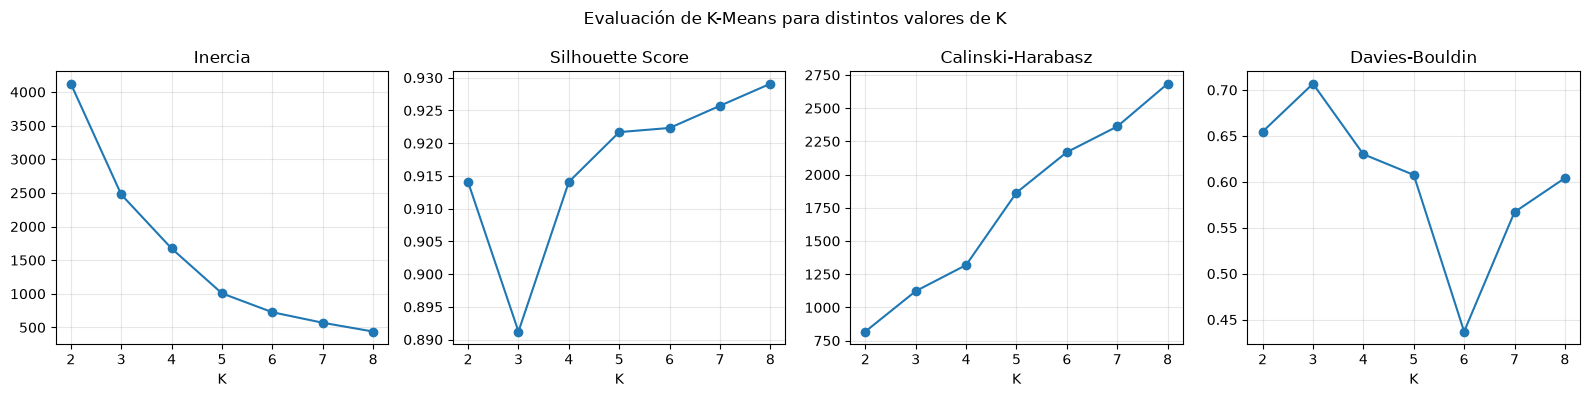

In [29]:

# ============================================================
# 5.3. VISUALIZACIÓN DE LAS MÉTRICAS INTERNAS
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True)

# Definir métricas a visualizar
metricas = [
    ("inercia", "Inercia", "K"),
    ("silueta", "Silhouette Score", "K"),
    ("calinski_harabasz", "Calinski-Harabasz", "K"),
    ("davies_bouldin", "Davies-Bouldin", "K")
]

# Graficar cada métrica
for ax, (columna, titulo, xlabel) in zip(axes, metricas):
    ax.plot(
        tabla_k_s.index,
        tabla_k_s[columna],
        marker="o"
    )
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_xticks(tabla_k_s.index)
    ax.grid(alpha=0.3)

plt.suptitle("Evaluación de K-Means para distintos valores de K")
plt.tight_layout()
plt.show()


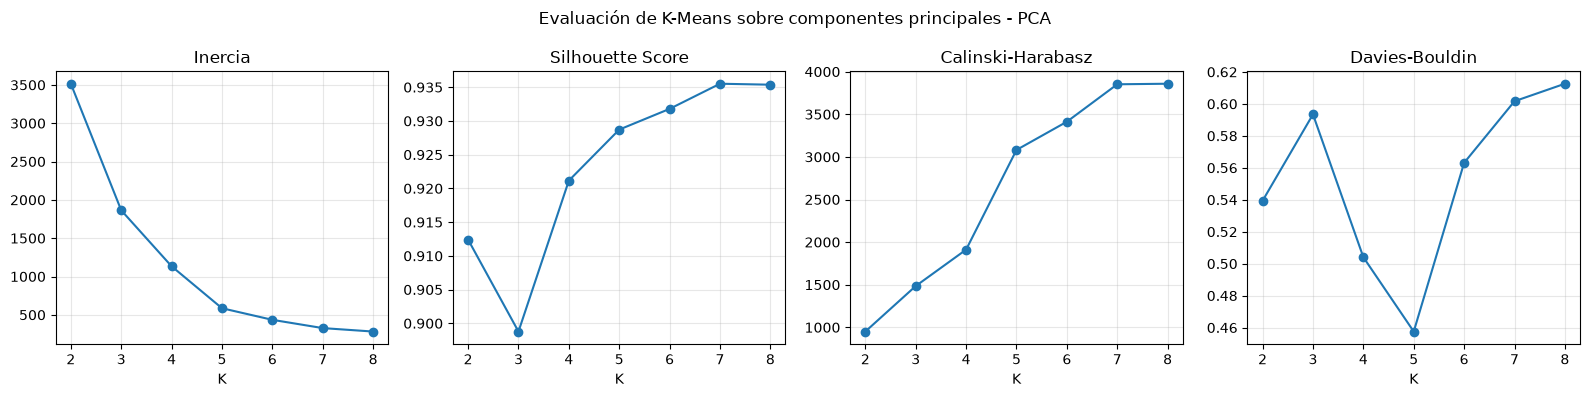

In [30]:
# ============================================================
# 5.4. VISUALIZACIÓN DE LAS MÉTRICAS INTERNAS - PCA
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True)

# Métricas a visualizar
metricas = [
    ("inercia", "Inercia", "K"),
    ("silueta", "Silhouette Score", "K"),
    ("calinski_harabasz", "Calinski-Harabasz", "K"),
    ("davies_bouldin", "Davies-Bouldin", "K")
]

# Graficar cada métrica
for ax, (columna, titulo, xlabel) in zip(axes, metricas):
    ax.plot(
        tabla_k_s_pca.index,
        tabla_k_s_pca[columna],
        marker="o"
    )

    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_xticks(tabla_k_s_pca.index)
    ax.grid(alpha=0.3)

plt.suptitle(
    "Evaluación de K-Means sobre componentes principales - PCA"
)

plt.tight_layout()
plt.show()

##### Selección de alternativas para el análisis detallado

_A partir de las métricas evaluadas en ambos enfoques, se seleccionaron K=4, K=5 y K=6 para profundizar la comparación. Estas alternativas permiten examinar distintas configuraciones de agrupamiento y analizar cómo la reducción de dimensionalidad modifica la estructura de los grupos._

_Si bien K=8 presenta los valores más altos de Silhouette y Calinski-Harabasz en ambos enfoques, la selección no se basa exclusivamente en las métricas internas. También se considera la distribución de las celdas entre los grupos y la interpretabilidad de los perfiles obtenidos. Por eso, se analizarán en detalle las tres alternativas en cada enfoque antes de definir los modelos principales._

_Dado que las métricas se calculan sobre las 1332 celdas, los resultados también están condicionados por la presencia del grupo mayoritario de 1128 celdas sin actividad sísmica. Por este motivo, se interpretan junto con la distribución de las celdas y las características de los perfiles obtenidos._

### 6. Comparación y selección de K

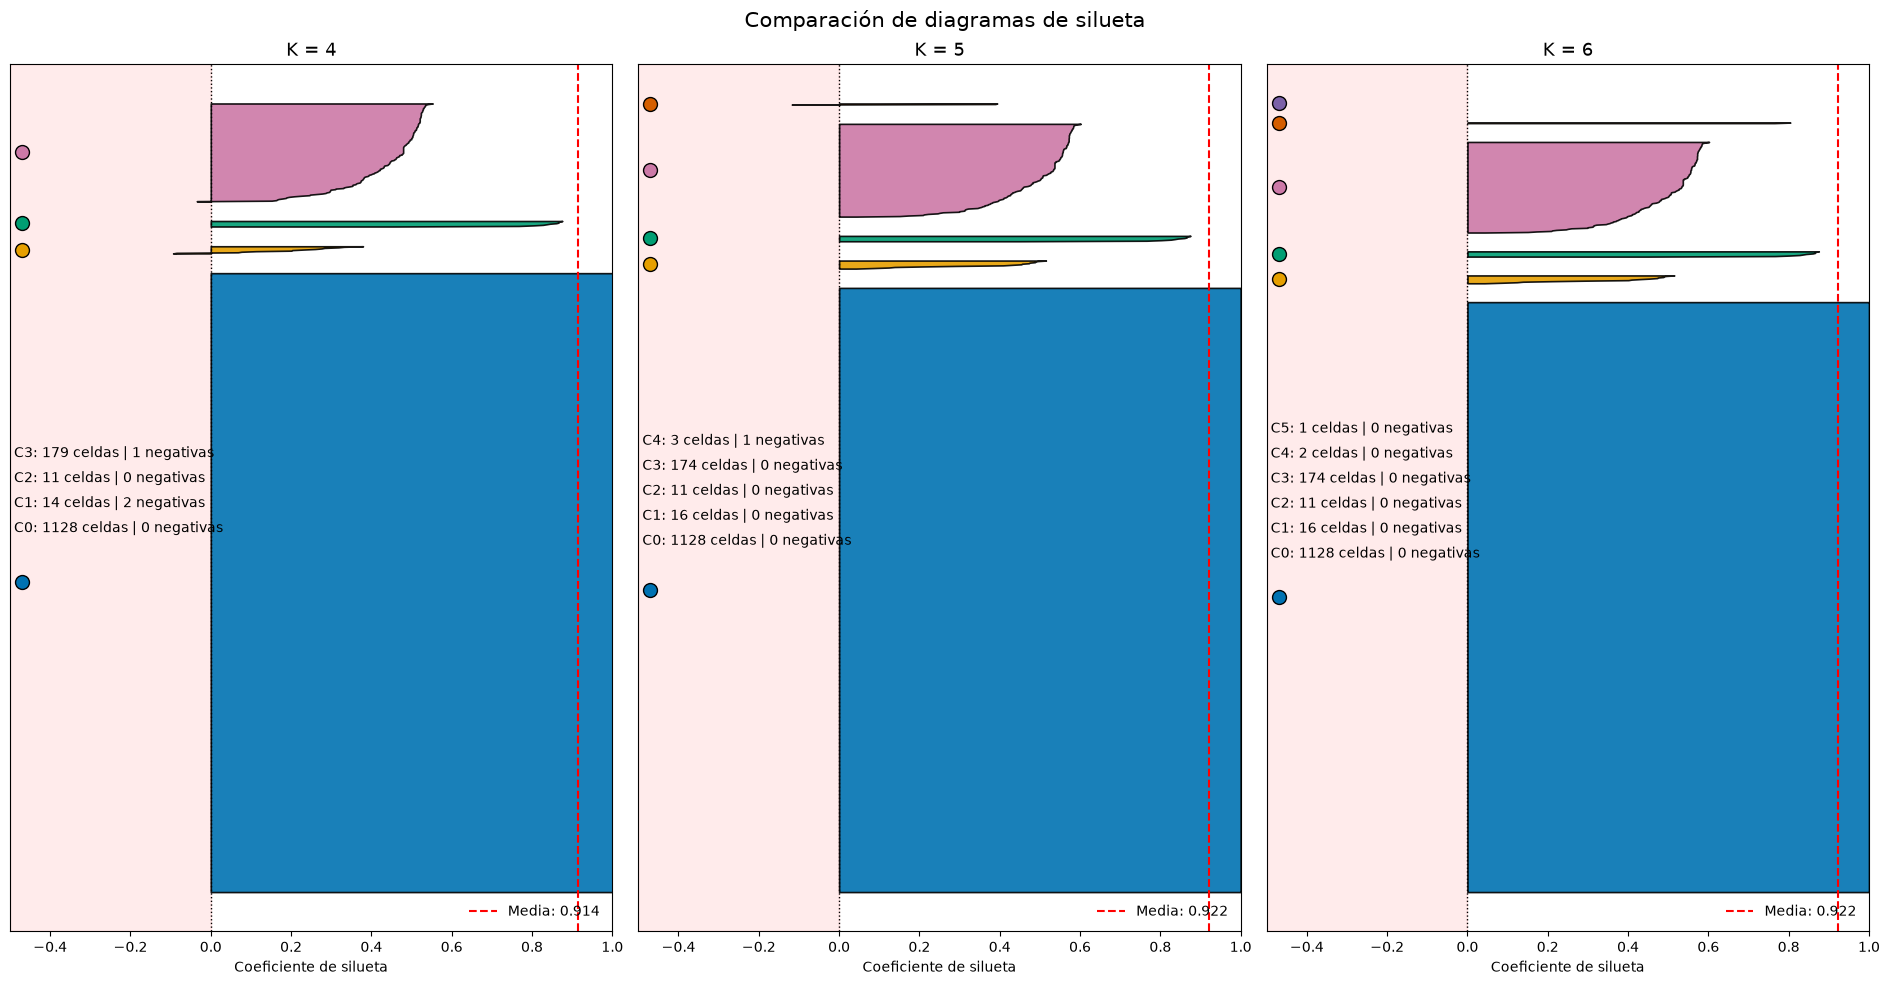

In [31]:

# ============================================================
# 6.1. DIAGRAMAS DE SILUETA 
# ============================================================

# Colores para distinguir los clusters
colores_clusters = [
    "#0072B2",  # Azul
    "#E69F00",  # Naranja
    "#009E73",  # Verde
    "#CC79A7",  # Rosa
    "#D55E00",  # Rojo anaranjado
    "#7B61A8"   # Violeta
]

# Valores de K a comparar
valores_k = [4, 5, 6]

# Separación vertical entre clusters
espacio_clusters = 35

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 10)
)

for ax, k in zip(axes, valores_k):

    # Etiquetas del modelo correspondiente
    etiquetas = modelos_kmeans[k].labels_

    # Coeficientes de silueta
    valores_silueta = silhouette_samples(
        datos_escalados,
        etiquetas
    )

    silueta_media = silhouette_score(
        datos_escalados,
        etiquetas
    )

    # Zona de valores negativos
    ax.axvspan(
        -0.5, 0,
        color="red",
        alpha=0.08
    )

    # Línea de referencia en cero
    ax.axvline(
        0,
        color="black",
        linewidth=1,
        linestyle=":"
    )

    y_inferior = 10
    informacion_clusters = []

    # Dibujar cada cluster
    for i in range(k):

        valores_cluster = np.sort(
            valores_silueta[etiquetas == i]
        )

        cantidad = len(valores_cluster)
        negativos = np.sum(valores_cluster < 0)

        y_superior = y_inferior + cantidad
        y_centro = (y_inferior + y_superior) / 2

        # Franja del cluster
        ax.fill_betweenx(
            np.arange(y_inferior, y_superior),
            0,
            valores_cluster,
            alpha=0.9,
            color=colores_clusters[i],
            edgecolor="black",
            linewidth=1.2
        )

        # Punto de color para identificar el cluster
        ax.scatter(
            [-0.47],
            [y_centro],
            color=colores_clusters[i],
            edgecolor="black",
            s=100,
            zorder=5
        )

        # Información del cluster
        informacion_clusters.append(
            f"C{i}: {cantidad} celdas | {negativos} negativas"
        )

        # Separación vertical
        y_inferior = y_superior + espacio_clusters

    # Lista de información en orden visual:
    # de arriba hacia abajo
    informacion_ordenada = informacion_clusters[::-1]

    ax.text(
        -0.49,
        y_inferior * 0.5,
        "\n".join(informacion_ordenada),
        fontsize=10,
        ha="left",
        va="center",
        linespacing=1.8
    )

    # Silueta promedio
    ax.axvline(
        silueta_media,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Media: {silueta_media:.3f}"
    )

    # Formato del gráfico
    ax.set_title(
        f"K = {k}",
        fontsize=13
    )

    ax.set_xlim(-0.5, 1)
    ax.set_xlabel("Coeficiente de silueta")
    ax.set_yticks([])

    ax.legend(
        loc="lower right",
        frameon=False
    )

fig.suptitle(
    "Comparación de diagramas de silueta",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [32]:

# ============================================================
# 6.2. COMPARACIÓN DE PERFILES 
# ============================================================

# Construir una única tabla comparativa de perfiles
perfiles_comparacion = []

for k in [4, 5, 6]:

    perfil_k = resumen_zonas.drop(
        columns=["cluster", "cluster_normalizado"],
        errors="ignore"
    ).copy()

    perfil_k["cluster"] = modelos_kmeans[k].labels_

    resumen_k = (
        perfil_k.groupby("cluster")
        .agg(
            cantidad_celdas=("zona_id", "count"),
            sismos_totales_media=("cantidad_total", "mean"),
            sismos_totales_mediana=("cantidad_total", "median"),
            meses_activos_media=("meses_activos", "mean"),
            maximo_mensual_media=("maximo_mensual", "mean"),
            magnitud_media=("magnitud_media", "mean"),
            profundidad_media=("profundidad_media", "mean")
        )
        .reset_index()
    )

    resumen_k["K"] = k

    perfiles_comparacion.append(resumen_k)

# Unificar los resultados
perfiles_comparacion = pd.concat(
    perfiles_comparacion,
    ignore_index=True
)

# Mostrar los perfiles de cada alternativa
for k in [4, 5, 6]:

    print(f"\nPERFILES PARA K={k}")

    display(
        perfiles_comparacion[
            perfiles_comparacion["K"] == k
        ]
        .set_index("cluster")
        .drop(columns="K")
        .round(2)
    )



PERFILES PARA K=4


,cantidad_celdas,sismos_totales_media,sismos_totales_mediana,meses_activos_media,maximo_mensual_media,magnitud_media,profundidad_media
cluster,,,,,,,
0,1128,0.00,0.0,0.00,0.00,NaN,NaN
1,14,295.36,217.5,86.93,38.64,4.59,93.05
2,11,6.73,7.0,6.09,1.27,4.81,553.37
3,179,12.08,4.0,8.10,2.93,4.60,47.10



PERFILES PARA K=5


,cantidad_celdas,sismos_totales_media,sismos_totales_mediana,meses_activos_media,maximo_mensual_media,magnitud_media,profundidad_media
cluster,,,,,,,
0,1128,0.00,0.0,0.00,0.00,NaN,NaN
1,16,175.06,161.5,72.69,22.00,4.59,89.98
2,11,6.73,7.0,6.09,1.27,4.81,553.37
3,174,9.74,4.0,6.87,2.47,4.60,46.13
4,3,600.67,515.0,103.00,94.67,4.61,89.48



PERFILES PARA K=6


,cantidad_celdas,sismos_totales_media,sismos_totales_mediana,meses_activos_media,maximo_mensual_media,magnitud_media,profundidad_media
cluster,,,,,,,
0,1128,0.00,0.0,0.00,0.00,NaN,NaN
1,16,175.06,161.5,72.69,22.00,4.59,89.98
2,11,6.73,7.0,6.09,1.27,4.81,553.37
3,174,9.74,4.0,6.87,2.47,4.60,46.13
4,2,504.50,504.5,95.50,133.50,4.74,38.80
5,1,793.00,793.0,118.00,17.00,4.34,190.83


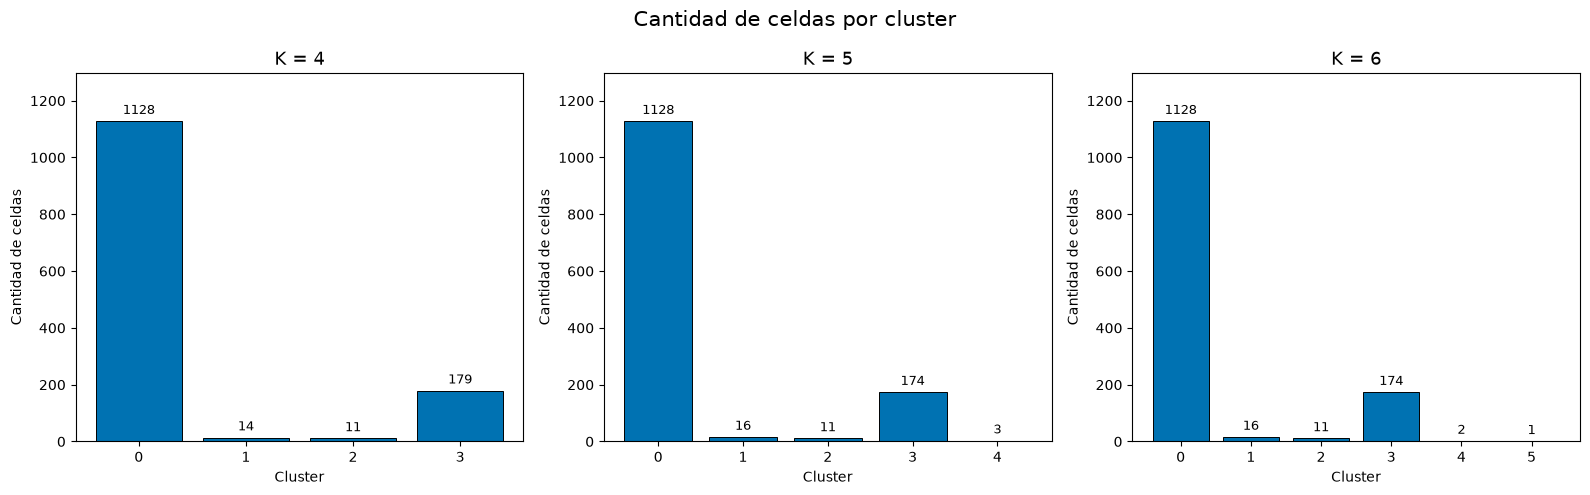

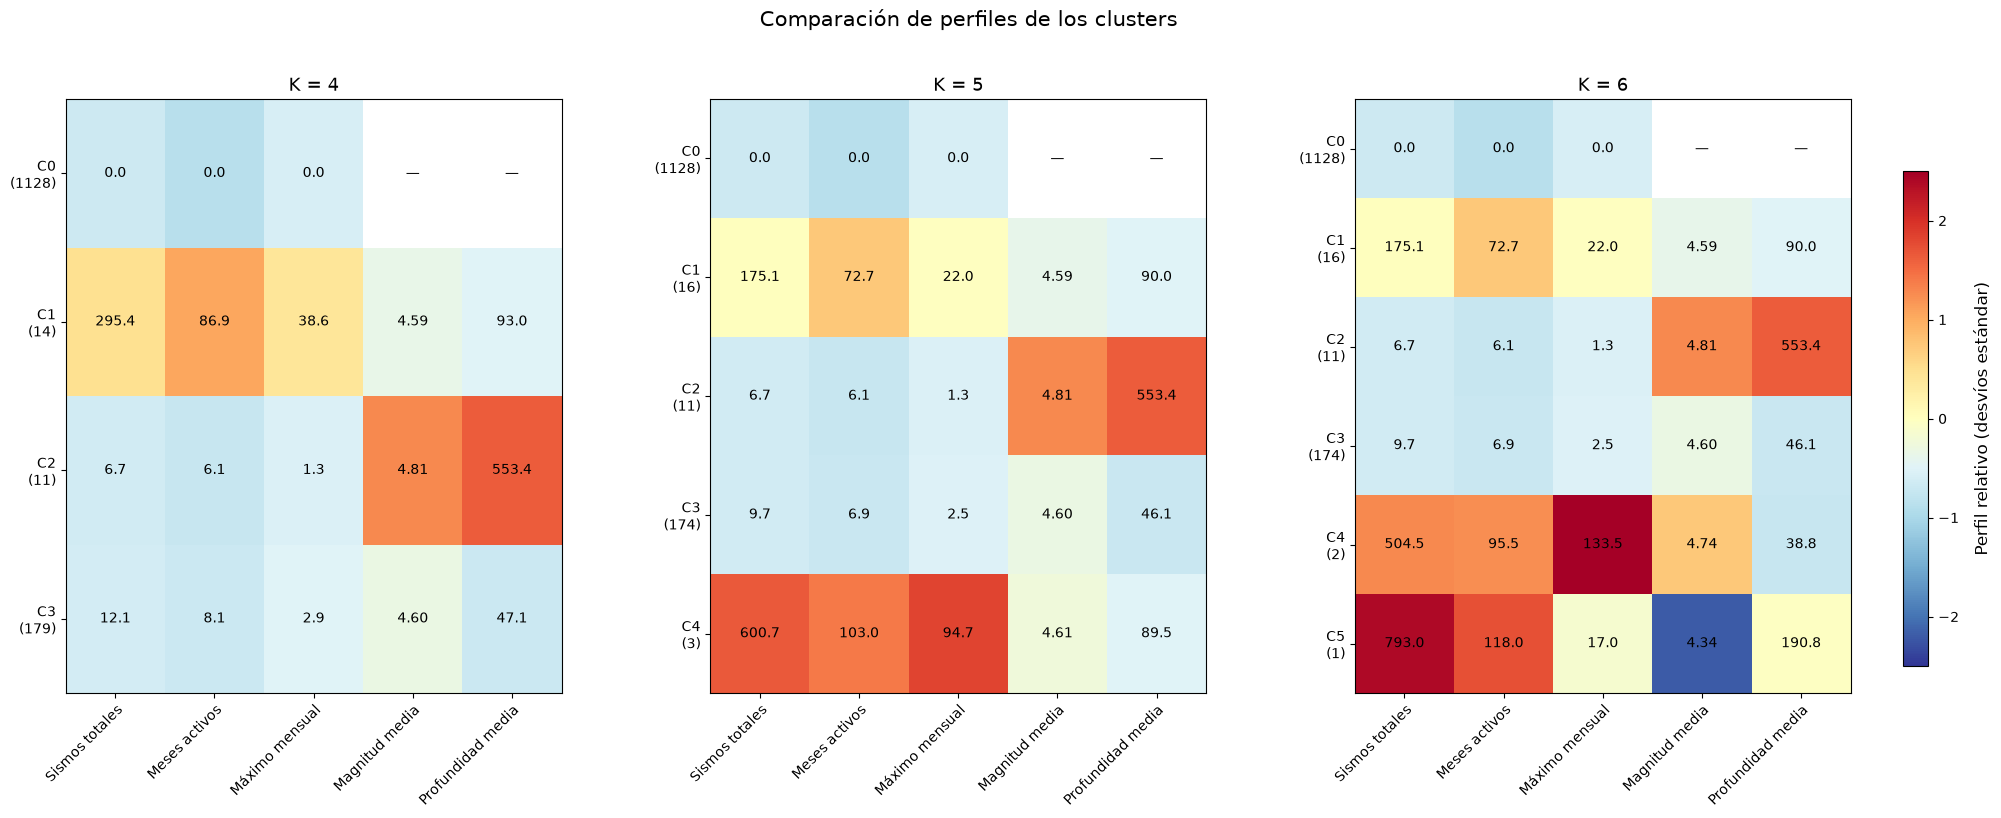

In [33]:

# ============================================================
# 6.3. VISUALIZACIÓN COMPARATIVA DE PERFILES
# ============================================================

# Variables que vamos a comparar
variables_perfil = [
    "sismos_totales_media",
    "meses_activos_media",
    "maximo_mensual_media",
    "magnitud_media",
    "profundidad_media"
]

nombres_variables = [
    "Sismos totales",
    "Meses activos",
    "Máximo mensual",
    "Magnitud media",
    "Profundidad media"
]


# ------------------------------------------------------------
# 6.3.1. GRÁFICO DE CANTIDAD DE CELDAS POR CLUSTER
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    sharey=False
)

for ax, k in zip(axes, [4, 5, 6]):

    datos_k = perfiles_comparacion[
        perfiles_comparacion["K"] == k
    ]

    barras = ax.bar(
        datos_k["cluster"].astype(str),
        datos_k["cantidad_celdas"],
        color="#0072B2",
        edgecolor="black",
        linewidth=0.7
    )

    ax.bar_label(
        barras,
        padding=3,
        fontsize=9
    )

    ax.set_title(f"K = {k}", fontsize=13)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Cantidad de celdas")
    ax.set_ylim(
        0,
        datos_k["cantidad_celdas"].max() * 1.15
    )

fig.suptitle(
    "Cantidad de celdas por cluster",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6.3.2. PREPARAR PERFILES PARA EL MAPA DE CALOR
# ------------------------------------------------------------

# Estandarizar las medias para comparar
# variables con distintas unidades y escalas.

# La estandarización se realiza sobre los perfiles promedio de los clusters, 
# considerando cada perfil con el mismo peso y no cada celda individual.

medias = perfiles_comparacion[variables_perfil]

media_global = medias.mean()
desvio_global = medias.std()

perfiles_estandarizados = (
    medias - media_global
) / desvio_global


# ------------------------------------------------------------
# 6.3.3. MAPAS DE CALOR PARA K=4, K=5 Y K=6
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(21, 9)
)

for ax, k in zip(axes, [4, 5, 6]):

    indices = perfiles_comparacion.index[
        perfiles_comparacion["K"] == k
    ]

    datos_k = perfiles_comparacion.loc[indices]
    matriz_k = perfiles_estandarizados.loc[indices]

    imagen = ax.imshow(
        matriz_k.values,
        cmap="RdYlBu_r",
        aspect="auto",
        vmin=-2.5,
        vmax=2.5
    )

    # Etiquetas de clusters en dos líneas
    etiquetas_y = [
        f"C{int(fila.cluster)}\n({int(fila.cantidad_celdas)})"
        for fila in datos_k.itertuples()
    ]

    ax.set_yticks(range(len(etiquetas_y)))
    ax.set_yticklabels(
        etiquetas_y,
        fontsize=10
    )

    # Etiquetas de variables en diagonal
    ax.set_xticks(range(len(nombres_variables)))
    ax.set_xticklabels(
        nombres_variables,
        rotation=45,
        ha="right",
        rotation_mode="anchor",
        fontsize=10
    )

    ax.set_title(f"K = {k}", fontsize=13)

    # Valores originales dentro de cada celda
    for i, (_, fila) in enumerate(datos_k.iterrows()):

        for j, variable in enumerate(variables_perfil):

            valor = fila[variable]

            if pd.isna(valor):
                texto = "—"
            elif variable == "magnitud_media":
                texto = f"{valor:.2f}"
            else:
                texto = f"{valor:.1f}"

            ax.text(
                j,
                i,
                texto,
                ha="center",
                va="center",
                fontsize=10,
                color="black"
            )


# Barra de color en un eje independiente
barra_ax = fig.add_axes([0.945, 0.25, 0.012, 0.55])

barra = fig.colorbar(
    imagen,
    cax=barra_ax
)

barra.set_label(
    "Perfil relativo (desvíos estándar)",
    fontsize=12,
    labelpad=10
)

fig.suptitle(
    "Comparación de perfiles de los clusters",
    fontsize=15
)

plt.subplots_adjust(
    left=0.07,
    right=0.92,
    bottom=0.22,
    top=0.88,
    wspace=0.30
)

plt.show()


In [34]:

# ============================================================
# 6.4. COMPARACIÓN DE ASIGNACIONES 
# ============================================================

# Construir tabla de asignaciones
comparacion_asignaciones = resumen_zonas[
    ["zona_id", "cantidad_total", "meses_activos", "maximo_mensual"]
].copy()

comparacion_asignaciones["cluster_k4"] = modelos_kmeans[4].labels_
comparacion_asignaciones["cluster_k5"] = modelos_kmeans[5].labels_
comparacion_asignaciones["cluster_k6"] = modelos_kmeans[6].labels_


# ------------------------------------------------------------
# 6.4.1. COMPARAR ASIGNACIONES ENTRE K=4 Y K=5
# ------------------------------------------------------------

print("DISTRIBUCIÓN DE CELDAS: K=4 FRENTE A K=5")

display(
    pd.crosstab(
        comparacion_asignaciones["cluster_k4"],
        comparacion_asignaciones["cluster_k5"],
        margins=True
    )
)


# ------------------------------------------------------------
# 6.4.2. COMPARAR ASIGNACIONES ENTRE K=4 Y K=6
# ------------------------------------------------------------

print("\nDISTRIBUCIÓN DE CELDAS: K=4 FRENTE A K=6")

display(
    pd.crosstab(
        comparacion_asignaciones["cluster_k4"],
        comparacion_asignaciones["cluster_k6"],
        margins=True
    )
)


# ------------------------------------------------------------
# 6.4.3. COMPARAR ASIGNACIONES ENTRE K=5 Y K=6
# ------------------------------------------------------------

print("\nDISTRIBUCIÓN DE CELDAS: K=5 FRENTE A K=6")

display(
    pd.crosstab(
        comparacion_asignaciones["cluster_k5"],
        comparacion_asignaciones["cluster_k6"],
        margins=True
    )
)


# ------------------------------------------------------------
# 6.4.4. IDENTIFICAR LAS CELDAS DEL GRUPO DE MAYOR ACTIVIDAD DE K=5
# ------------------------------------------------------------

cluster_mayor_actividad = (
    comparacion_asignaciones
    .groupby("cluster_k5")["cantidad_total"]
    .mean()
    .idxmax()
)

celdas_extremas = (
    comparacion_asignaciones[
        comparacion_asignaciones["cluster_k5"] == cluster_mayor_actividad
    ]
    .sort_values("cantidad_total", ascending=False)
)

print("\nCELDAS DEL GRUPO DE MAYOR ACTIVIDAD DE K=5:")

display(celdas_extremas)


DISTRIBUCIÓN DE CELDAS: K=4 FRENTE A K=5


cluster_k5,0,1,2,3,4,All
cluster_k4,,,,,,
0,1128,0,0,0,0,1128
1,0,11,0,0,3,14
2,0,0,11,0,0,11
3,0,5,0,174,0,179
All,1128,16,11,174,3,1332



DISTRIBUCIÓN DE CELDAS: K=4 FRENTE A K=6


cluster_k6,0,1,2,3,4,5,All
cluster_k4,,,,,,,
0,1128,0,0,0,0,0,1128
1,0,11,0,0,2,1,14
2,0,0,11,0,0,0,11
3,0,5,0,174,0,0,179
All,1128,16,11,174,2,1,1332



DISTRIBUCIÓN DE CELDAS: K=5 FRENTE A K=6


cluster_k6,0,1,2,3,4,5,All
cluster_k5,,,,,,,
0,1128,0,0,0,0,0,1128
1,0,16,0,0,0,0,16
2,0,0,11,0,0,0,11
3,0,0,0,174,0,0,174
4,0,0,0,0,2,1,3
All,1128,16,11,174,2,1,1332



CELDAS DEL GRUPO DE MAYOR ACTIVIDAD DE K=5:


,zona_id,cantidad_total,meses_activos,maximo_mensual,cluster_k4,cluster_k5,cluster_k6
92,Z00093,793,118,17,1,4,5
1289,Z01290,515,94,120,1,4,4
1271,Z01272,494,97,147,1,4,4


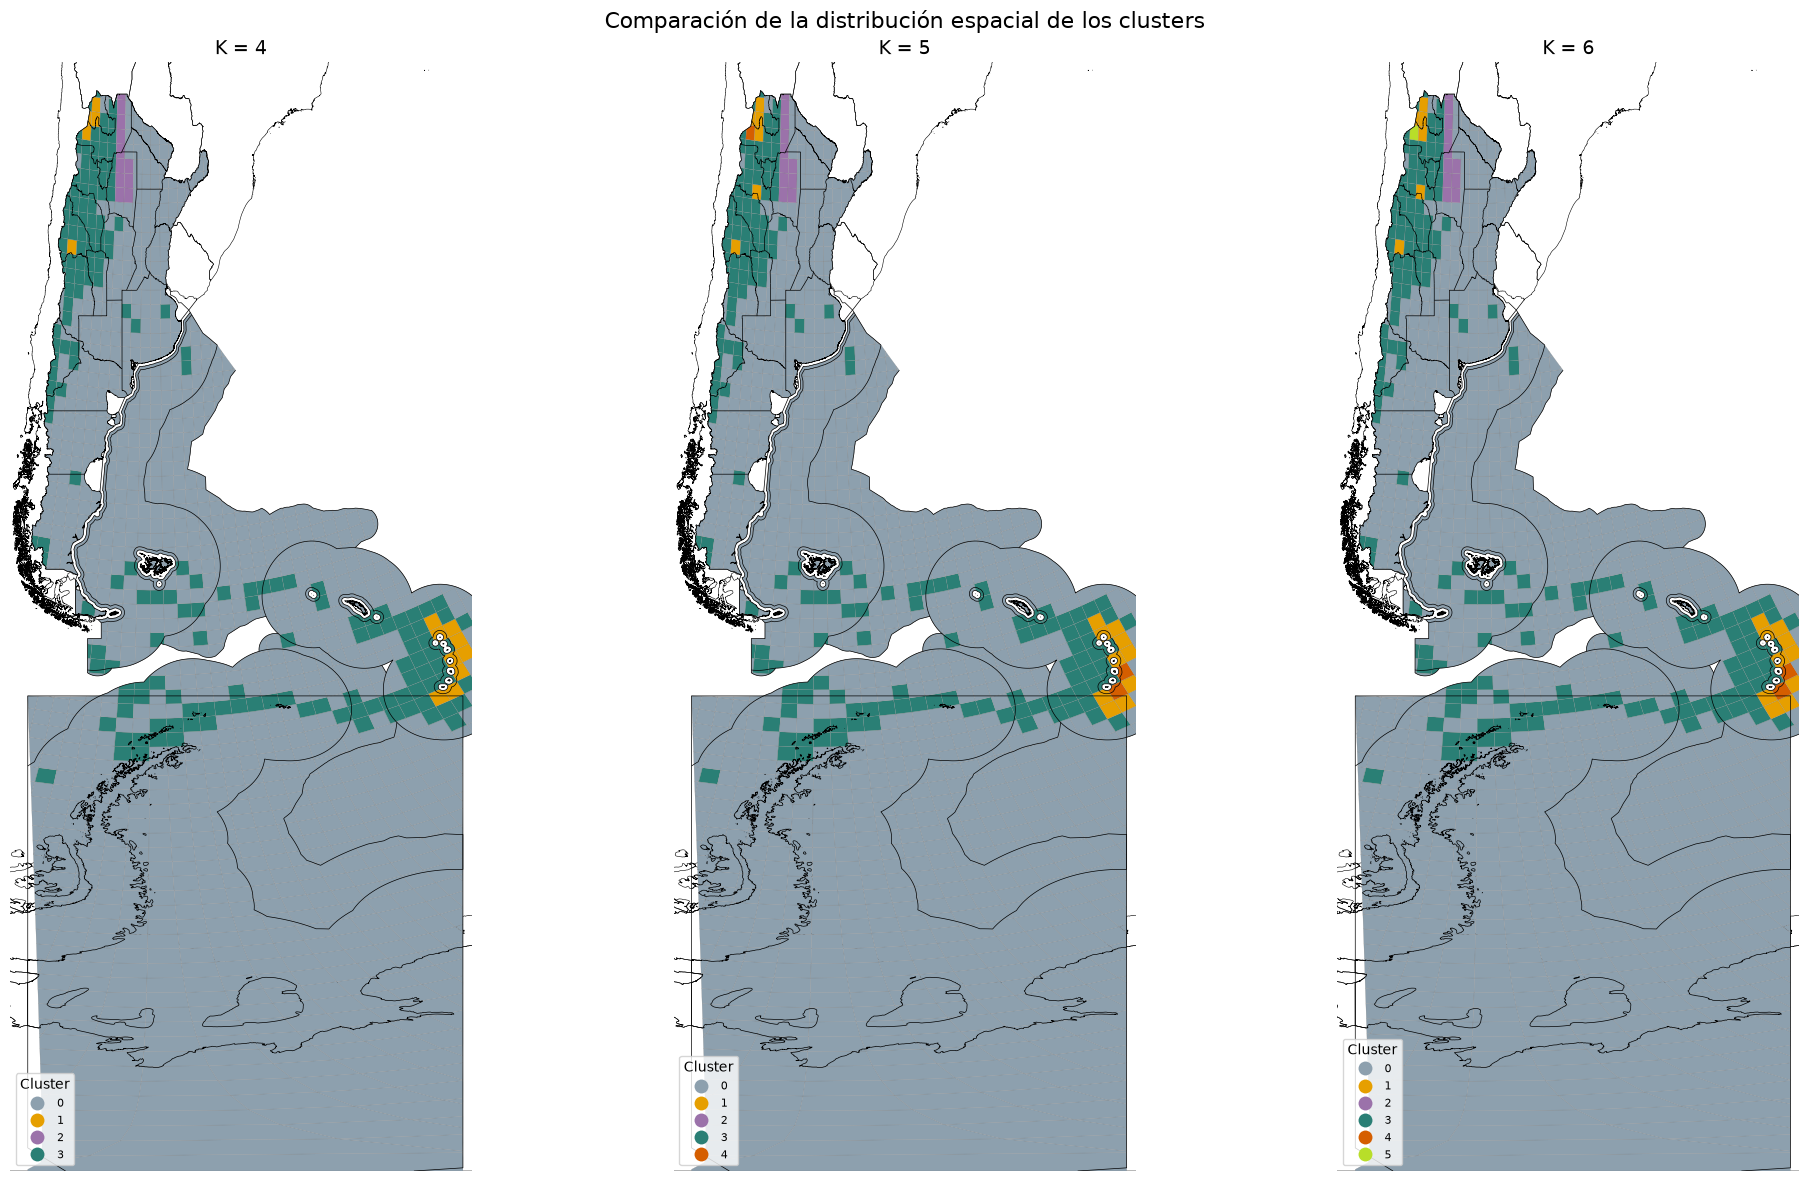

In [35]:
# ============================================================
# 6.4.5. COMPARACIÓN ESPACIAL
# ============================================================

# Paletas con colores diferenciados
paletas = {
    4: ["#8DA0AE", "#E69F00", "#9B72AA", "#2A7F75"],
    5: ["#8DA0AE", "#E69F00", "#9B72AA", "#2A7F75", "#D55E00"],
    6: ["#8DA0AE", "#E69F00", "#9B72AA", "#2A7F75", "#D55E00", "#B8DE29"]
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(21, 12)
)

for ax, k in zip(axes, [4, 5, 6]):

    # Asignar etiquetas del modelo correspondiente a cada celda
    asignaciones_k = pd.DataFrame({
        "zona_id": resumen_zonas["zona_id"].to_numpy(),
        "cluster": modelos_kmeans[k].labels_
    })

    grilla_k = grilla_recortada.merge(
        asignaciones_k,
        on="zona_id",
        how="left"
    )

    # Referencias geográficas
    ign_sudam.plot(
        ax=ax,
        facecolor="none",
        edgecolor="black",
        linewidth=0.4
    )

    # Grilla coloreada según cluster
    grilla_k.to_crs("EPSG:4326").plot(
        column="cluster",
        categorical=True,
        cmap=ListedColormap(paletas[k]),
        legend=True,
        ax=ax,
        edgecolor="gray",
        linewidth=0.15,
        legend_kwds={
            "title": "Cluster",
            "loc": "lower left",
            "fontsize": 8
        }
    )

    ign_arg.plot(
        ax=ax,
        color="black",
        linewidth=0.5
    )

    ax.set_xlim(-76, -24)
    ax.set_ylim(-90, -20)
    ax.set_title(f"K = {k}", fontsize=14)
    ax.set_axis_off()

fig.suptitle(
    "Comparación de la distribución espacial de los clusters",
    fontsize=16
)

plt.tight_layout()
plt.show()


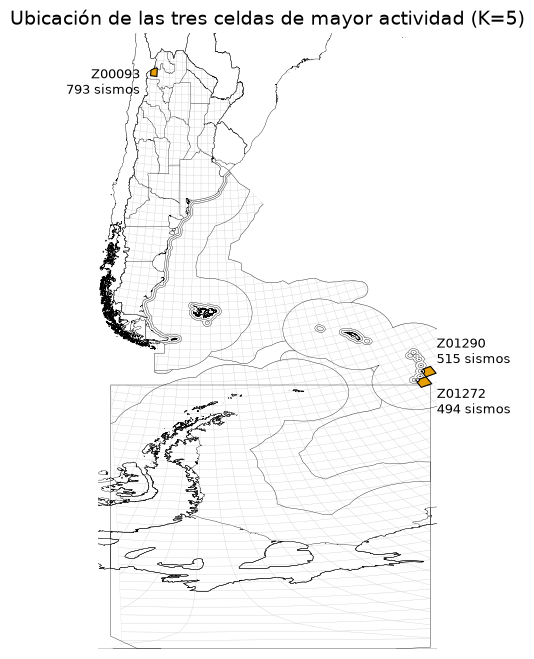

Asignación de las tres celdas:


,zona_id,cantidad_total,cluster_k4,cluster_k5,cluster_k6
0,Z00093,793,1,4,5
2,Z01290,515,1,4,4
1,Z01272,494,1,4,4


In [36]:
# ============================================================
# 6.4.6. ANÁLISIS DE LAS SUBDIVISIONES DE LOS CLUSTERS
#    - UBICACIÓN DE LAS TRES CELDAS EXTREMAS DE K=5 -
# ============================================================


# Unir las celdas extremas con la geometría de la grilla
zonas_extremas = grilla_recortada.merge(
    celdas_extremas[
        ["zona_id", "cantidad_total", "cluster_k4", "cluster_k5"]
    ],
    on="zona_id",
    how="inner"
)

# Incorporar la asignación correspondiente a K=6
asignaciones_k6 = pd.DataFrame({
    "zona_id": resumen_zonas["zona_id"].to_numpy(),
    "cluster_k6": modelos_kmeans[6].labels_
})

zonas_extremas = zonas_extremas.merge(
    asignaciones_k6,
    on="zona_id",
    how="left"
)

# Reproyectar las capas al mismo CRS del mapa comparativo
grilla_mapa = grilla_recortada.to_crs("EPSG:4326")
zonas_extremas_mapa = zonas_extremas.to_crs("EPSG:4326")

ign_sudam_mapa = ign_sudam.to_crs("EPSG:4326")
ign_arg_mapa = ign_arg.to_crs("EPSG:4326")

# ------------------------------------------------------------
# MAPA
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 8))

# Referencia geográfica: Sudamérica
ign_sudam_mapa.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.25
)

# Grilla completa
grilla_mapa.boundary.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.15
)

# Referencia geográfica: territorio argentino,
# incluida la silueta antártica
ign_arg_mapa.plot(
    ax=ax,
    color="black",
    linewidth=0.25
)

# Resaltar las tres celdas de mayor actividad
zonas_extremas_mapa.plot(
    ax=ax,
    color="#E69F00",
    edgecolor="black",
    linewidth=0.8,
    zorder=5
)

# Etiquetas de las celdas
for _, fila in zonas_extremas_mapa.iterrows():

    punto = fila.geometry.representative_point()

    if fila["zona_id"] == "Z01290":
        desplazamiento = (5, 6)

    elif fila["zona_id"] == "Z01272":
        desplazamiento = (9, -22)

    else:
        desplazamiento = (-10, -15)

    ax.annotate(
        f"{fila['zona_id']}\n{fila['cantidad_total']} sismos",
        (punto.x, punto.y),
        xytext=desplazamiento,
        textcoords="offset points",
        fontsize=9,
        ha="right" if fila["zona_id"] == "Z00093" else "left"
    )

# Límites y formato
ax.set_xlim(-76, -24)
ax.set_ylim(-90, -20)

ax.set_title(
    "Ubicación de las tres celdas de mayor actividad (K=5)",
    fontsize=14
)

ax.set_axis_off()

plt.show()

# ------------------------------------------------------------
# TABLA DE ASIGNACIONES
# ------------------------------------------------------------

print("Asignación de las tres celdas:")

display(
    zonas_extremas[
        [
            "zona_id",
            "cantidad_total",
            "cluster_k4",
            "cluster_k5",
            "cluster_k6"
        ]
    ].sort_values(
        "cantidad_total",
        ascending=False
    )
)

##### Síntesis comparativa y selección del modelo principal

La comparación de las alternativas permitió identificar distintas formas de organizar las celdas según sus características de actividad sísmica.

Las tres configuraciones conservaron un grupo mayoritario de **1128 celdas sin actividad sísmica** durante el período analizado y mantuvieron un grupo de **11 celdas con actividad poco frecuente y profundidades medias elevadas**. Las principales diferencias se observaron en la subdivisión de las zonas con mayor actividad.

Con **K=4**, se obtuvo una clasificación más compacta, que distingue cuatro perfiles generales: celdas sin actividad, zonas de actividad elevada y sostenida, zonas de actividad poco frecuente y profunda, y zonas de baja actividad.

Con **K=5**, el grupo de mayor actividad se subdividió, identificando tres celdas extremas. Dos corresponden a la región de las Islas Sandwich del Sur y la restante se ubica en el norte de Argentina, en la región de Salta. Esta configuración permitió reconocer zonas con valores particularmente elevados de actividad.

Con **K=6**, esas tres celdas quedaron distribuidas en dos grupos: las dos celdas de la región de las Islas Sandwich del Sur y la celda de la región de Salta. Esta separación permite distinguir agrupaciones con diferencias en sus características de actividad, cuya evolución temporal se analiza específicamente en la sección dedicada al episodio de agosto de 2021.

Si bien K=5 y K=6 obtuvieron mejores resultados en las métricas internas de evaluación, se selecciona **K=4 como modelo principal** por ofrecer una clasificación más compacta y facilitar la interpretación general de los patrones espaciales. Las alternativas K=5 y K=6 se conservan como análisis complementarios, ya que permiten profundizar en la heterogeneidad de las zonas de mayor actividad.

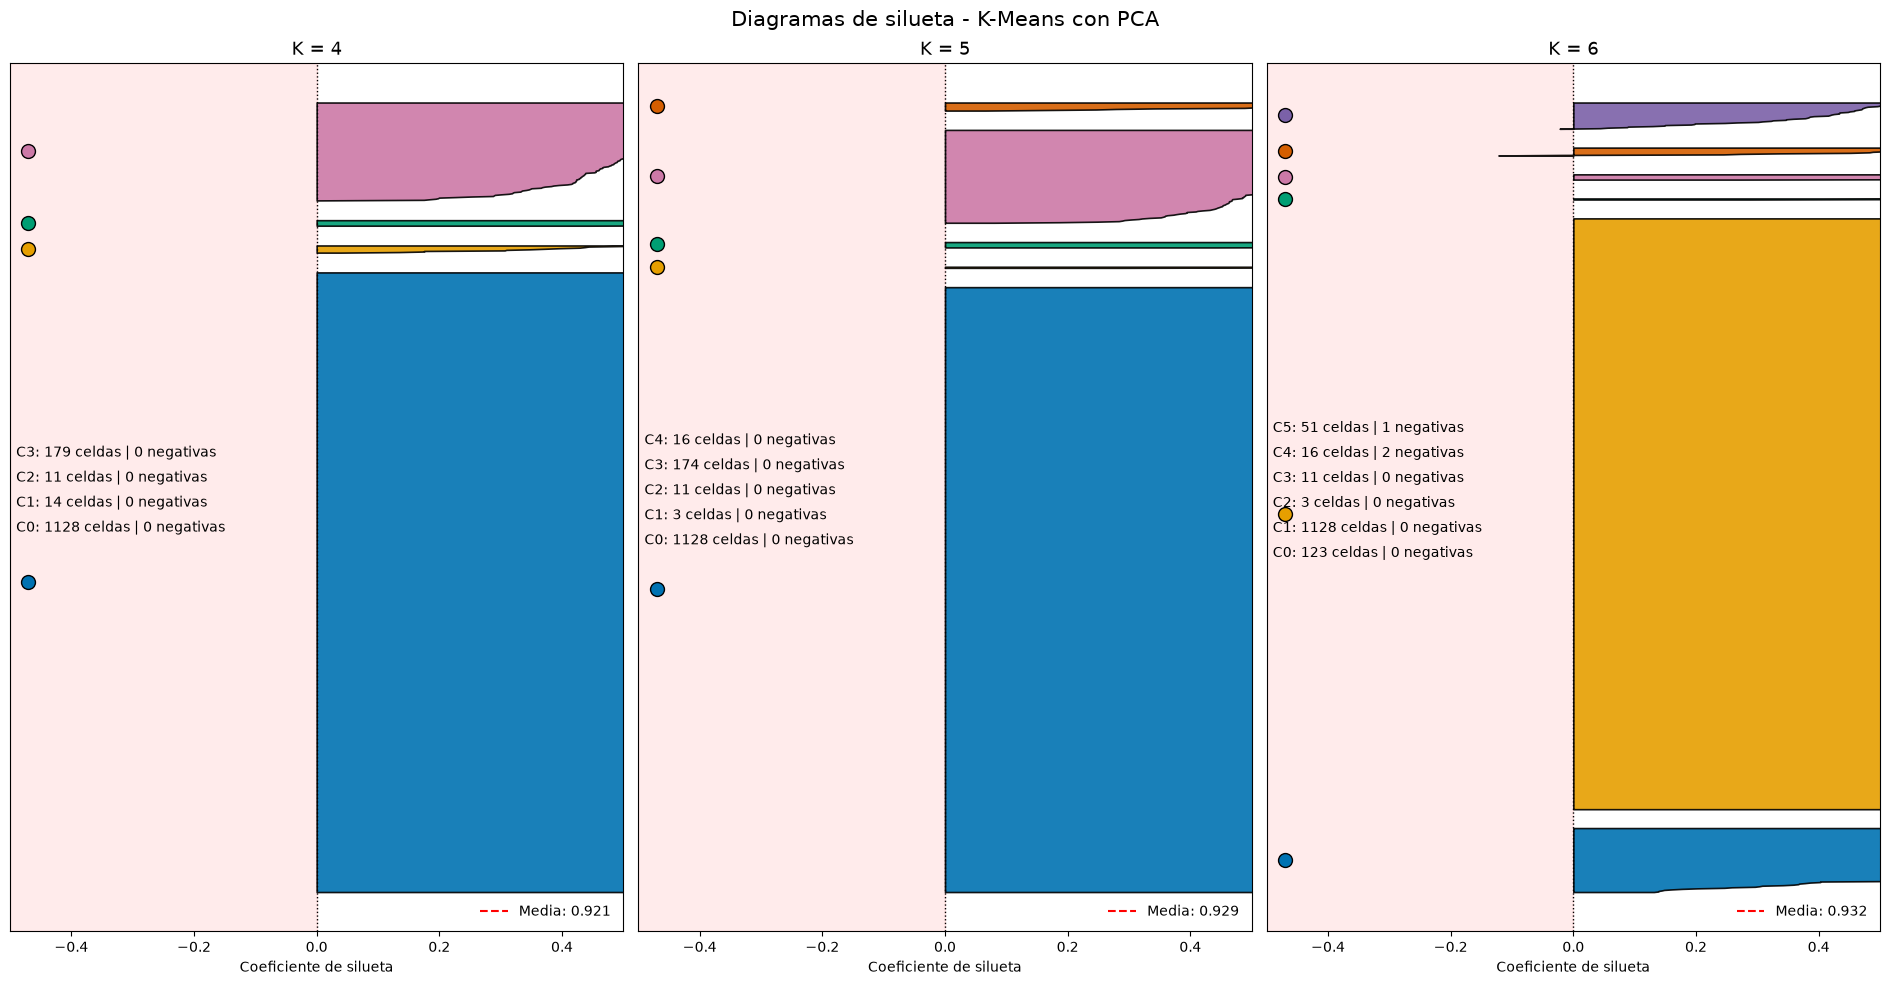

In [64]:
# ============================================================
# 6.5. DIAGRAMAS DE SILUETA - MODELO CON PCA
# ============================================================

# Colores para distinguir los clusters
colores_clusters = [
    "#0072B2",  # Azul
    "#E69F00",  # Naranja
    "#009E73",  # Verde
    "#CC79A7",  # Rosa
    "#D55E00",  # Rojo anaranjado
    "#7B61A8"   # Violeta
]

# Valores de K a comparar
valores_k = [4, 5, 6]

# Separación vertical entre clusters
espacio_clusters = 35

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 10)
)

for ax, k in zip(axes, valores_k):

    # Etiquetas del modelo PCA correspondiente
    etiquetas = modelos_kmeans_pca[k].labels_

    # Coeficientes de silueta
    valores_silueta = silhouette_samples(
        datos_pca,
        etiquetas
    )

    silueta_media = silhouette_score(
        datos_pca,
        etiquetas
    )

    # Zona de valores negativos
    ax.axvspan(
        -0.5, 0,
        color="red",
        alpha=0.08
    )

    # Línea de referencia en cero
    ax.axvline(
        0,
        color="black",
        linewidth=1,
        linestyle=":"
    )

    y_inferior = 10
    informacion_clusters = []

    # Dibujar cada cluster
    for i in range(k):

        valores_cluster = np.sort(
            valores_silueta[etiquetas == i]
        )

        cantidad = len(valores_cluster)
        negativos = np.sum(valores_cluster < 0)

        y_superior = y_inferior + cantidad
        y_centro = (y_inferior + y_superior) / 2

        # Franja del cluster
        ax.fill_betweenx(
            np.arange(y_inferior, y_superior),
            0,
            valores_cluster,
            alpha=0.9,
            color=colores_clusters[i],
            edgecolor="black",
            linewidth=1.2
        )

        # Punto de color para identificar el cluster
        ax.scatter(
            [-0.47],
            [y_centro],
            color=colores_clusters[i],
            edgecolor="black",
            s=100,
            zorder=5
        )

        # Información del cluster
        informacion_clusters.append(
            f"C{i}: {cantidad} celdas | {negativos} negativas"
        )

        # Separación vertical
        y_inferior = y_superior + espacio_clusters

    # Lista de información en orden visual
    informacion_ordenada = informacion_clusters[::-1]

    ax.text(
        -0.49,
        y_inferior * 0.5,
        "\n".join(informacion_ordenada),
        fontsize=10,
        ha="left",
        va="center",
        linespacing=1.8
    )

    # Silueta promedio
    ax.axvline(
        silueta_media,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Media: {silueta_media:.3f}"
    )

    # Formato del gráfico
    ax.set_title(
        f"K = {k}",
        fontsize=13
    )

    ax.set_xlim(-0.5, 0.5)
    ax.set_xlabel("Coeficiente de silueta")
    ax.set_yticks([])

    ax.legend(
        loc="lower right",
        frameon=False
    )

fig.suptitle(
    "Diagramas de silueta - K-Means con PCA",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [38]:
# ==================================================================
# 6.6. Diagnóstico de las celdas con siluetas negativas en K=6 (PCA)
# ==================================================================

# En las comparaciones de esta sección se conservan las etiquetas originales
# asignadas por K-Means para cada alternativa.


# 6.6.1. Identificación y caracterización de las celdas.

# Calcular siluetas individuales para K=6
etiquetas_k6 = modelos_kmeans_pca[6].labels_

siluetas_k6 = silhouette_samples(
    datos_pca,
    etiquetas_k6
)

# Crear tabla con los datos originales y la silueta
diagnostico_k6 = resumen_zonas.copy()

diagnostico_k6["cluster"] = etiquetas_k6
diagnostico_k6["silueta"] = siluetas_k6

# Filtrar las celdas del cluster 4 con silueta negativa
celdas_negativas_k6 = diagnostico_k6[
    (diagnostico_k6["cluster"] == 4) &
    (diagnostico_k6["silueta"] < 0)
].sort_values("silueta")

# Mostrar únicamente los casos con silueta negativa
display(
    celdas_negativas_k6[
        [
            "zona_id",
            "cantidad_total",
            "meses_activos",
            "maximo_mensual",
            "magnitud_media",
            "profundidad_media",
            "silueta"
        ]
    ].round(4)
)

,zona_id,cantidad_total,meses_activos,maximo_mensual,magnitud_media,profundidad_media,silueta
130,Z00131,81,62,4,4.4630,164.5455,-0.1221
134,Z00135,94,59,7,4.4021,194.9223,-0.0189


In [39]:
# 6.6.2. Comparación de asignaciones y distancias entre K=5 y K=6.

zonas_revisar = ["Z00131", "Z00135"]

resultados = []

for k in [5, 6]:

    etiquetas = modelos_kmeans_pca[k].labels_
    siluetas = silhouette_samples(datos_pca, etiquetas)
    distancias = pairwise_distances(datos_pca)

    for zona in zonas_revisar:

        # Ubicación de la zona en los datos
        idx = resumen_zonas.index[
            resumen_zonas["zona_id"] == zona
        ][0]

        cluster_propio = etiquetas[idx]

        # Distancia media al propio cluster (sin incluir la zona)
        mascara_propio = etiquetas == cluster_propio
        mascara_propio[idx] = False

        distancia_propia = distancias[idx, mascara_propio].mean()

        # Distancia media a cada uno de los otros clusters
        distancias_otros = {}

        for cluster in sorted(set(etiquetas)):
            if cluster == cluster_propio:
                continue

            mascara = etiquetas == cluster
            distancias_otros[cluster] = distancias[idx, mascara].mean()

        cluster_mas_cercano = min(
            distancias_otros,
            key=distancias_otros.get
        )

        resultados.append({
            "K": k,
            "zona_id": zona,
            "cluster_propio": cluster_propio,
            "silueta": siluetas[idx],
            "distancia_propia": distancia_propia,
            "cluster_mas_cercano": cluster_mas_cercano,
            "distancia_otro_cluster": distancias_otros[cluster_mas_cercano]
        })

tabla_diagnostico = pd.DataFrame(resultados)

display(tabla_diagnostico.round(4))

,K,zona_id,cluster_propio,silueta,distancia_propia,cluster_mas_cercano,distancia_otro_cluster
0,5,Z00131,4,0.0663,5.0018,3,5.3569
1,5,Z00135,4,0.1555,4.9089,3,5.8132
2,6,Z00131,4,-0.1221,5.0018,5,4.3912
3,6,Z00135,4,-0.0189,4.9089,5,4.8159


##### Interpretación de las siluetas negativas

_El análisis permitió identificar dos celdas del cluster C4 de K=6 (PCA) con valores de silueta negativos, lo que indica que presentan mayor proximidad a otro grupo que al cluster al que fueron asignadas. Al examinar sus características y distancias entre clusters para K=5 y K=6, se observó que su comportamiento está relacionado, entre otros factores, con sus mayores profundidades medias y con los cambios en la estructura de agrupamiento al aumentar K. Estos resultados muestran que una silueta negativa no implica necesariamente una asignación incorrecta, sino que puede reflejar características particulares de las celdas y su proximidad a otros grupos._

In [40]:
# ============================================================
# 6.7. COMPARACIÓN DE PERFILES - PCA
# ============================================================

# Construir una única tabla comparativa de perfiles
perfiles_comparacion_pca = []

for k in [4, 5, 6]:

    perfil_k = resumen_zonas.drop(
        columns=["cluster", "cluster_normalizado"],
        errors="ignore"
    ).copy()

    perfil_k["cluster"] = modelos_kmeans_pca[k].labels_

    resumen_k = (
        perfil_k.groupby("cluster")
        .agg(
            cantidad_celdas=("zona_id", "count"),
            sismos_totales_media=("cantidad_total", "mean"),
            sismos_totales_mediana=("cantidad_total", "median"),
            meses_activos_media=("meses_activos", "mean"),
            maximo_mensual_media=("maximo_mensual", "mean"),
            magnitud_media=("magnitud_media", "mean"),
            profundidad_media=("profundidad_media", "mean")
        )
        .reset_index()
    )

    resumen_k["K"] = k

    perfiles_comparacion_pca.append(resumen_k)

# Unificar los resultados
perfiles_comparacion_pca = pd.concat(
    perfiles_comparacion_pca,
    ignore_index=True
)

# Mostrar los perfiles de cada alternativa
for k in [4, 5, 6]:

    print(f"\nPERFILES PCA PARA K={k}")

    display(
        perfiles_comparacion_pca[
            perfiles_comparacion_pca["K"] == k
        ]
        .set_index("cluster")
        .drop(columns="K")
        .round(2)
    )


PERFILES PCA PARA K=4


,cantidad_celdas,sismos_totales_media,sismos_totales_mediana,meses_activos_media,maximo_mensual_media,magnitud_media,profundidad_media
cluster,,,,,,,
0,1128,0.00,0.0,0.00,0.00,NaN,NaN
1,14,295.36,217.5,86.93,38.64,4.59,93.05
2,11,6.73,7.0,6.09,1.27,4.81,553.37
3,179,12.08,4.0,8.10,2.93,4.60,47.10



PERFILES PCA PARA K=5


,cantidad_celdas,sismos_totales_media,sismos_totales_mediana,meses_activos_media,maximo_mensual_media,magnitud_media,profundidad_media
cluster,,,,,,,
0,1128,0.00,0.0,0.00,0.00,NaN,NaN
1,3,600.67,515.0,103.00,94.67,4.61,89.48
2,11,6.73,7.0,6.09,1.27,4.81,553.37
3,174,9.74,4.0,6.87,2.47,4.60,46.13
4,16,175.06,161.5,72.69,22.00,4.59,89.98



PERFILES PCA PARA K=6


,cantidad_celdas,sismos_totales_media,sismos_totales_mediana,meses_activos_media,maximo_mensual_media,magnitud_media,profundidad_media
cluster,,,,,,,
0,123,7.61,2.0,4.41,2.80,4.64,14.20
1,1128,0.00,0.0,0.00,0.00,NaN,NaN
2,3,600.67,515.0,103.00,94.67,4.61,89.48
3,11,6.73,7.0,6.09,1.27,4.81,553.37
4,16,175.06,161.5,72.69,22.00,4.59,89.98
5,51,14.88,8.0,12.80,1.67,4.49,123.14


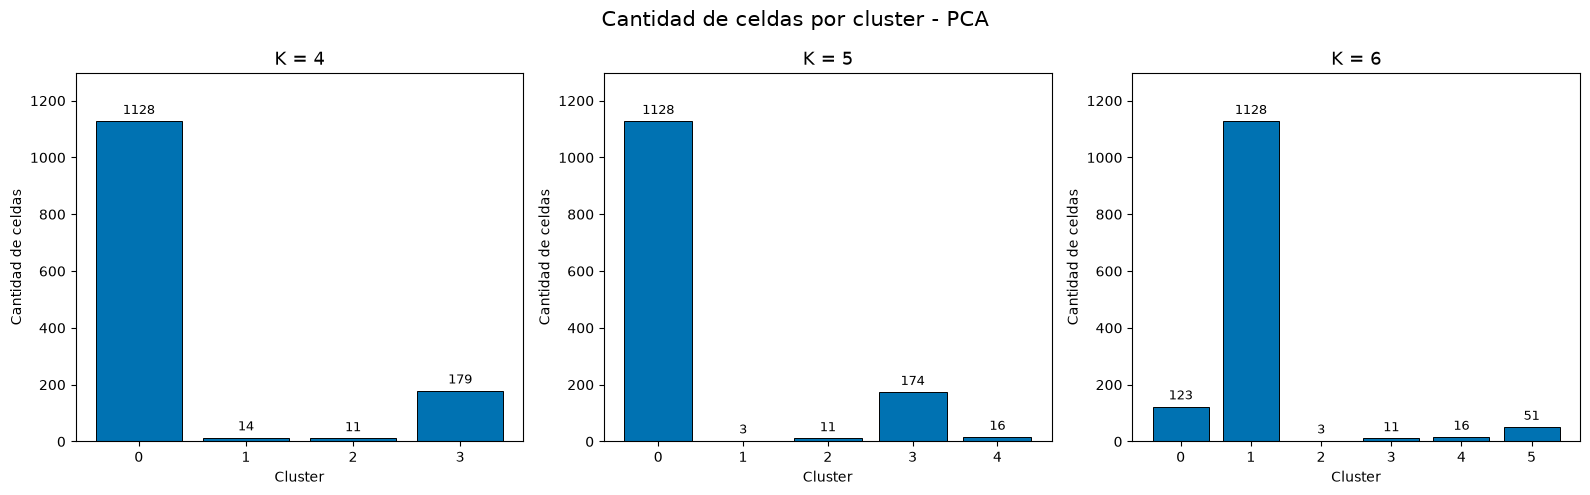

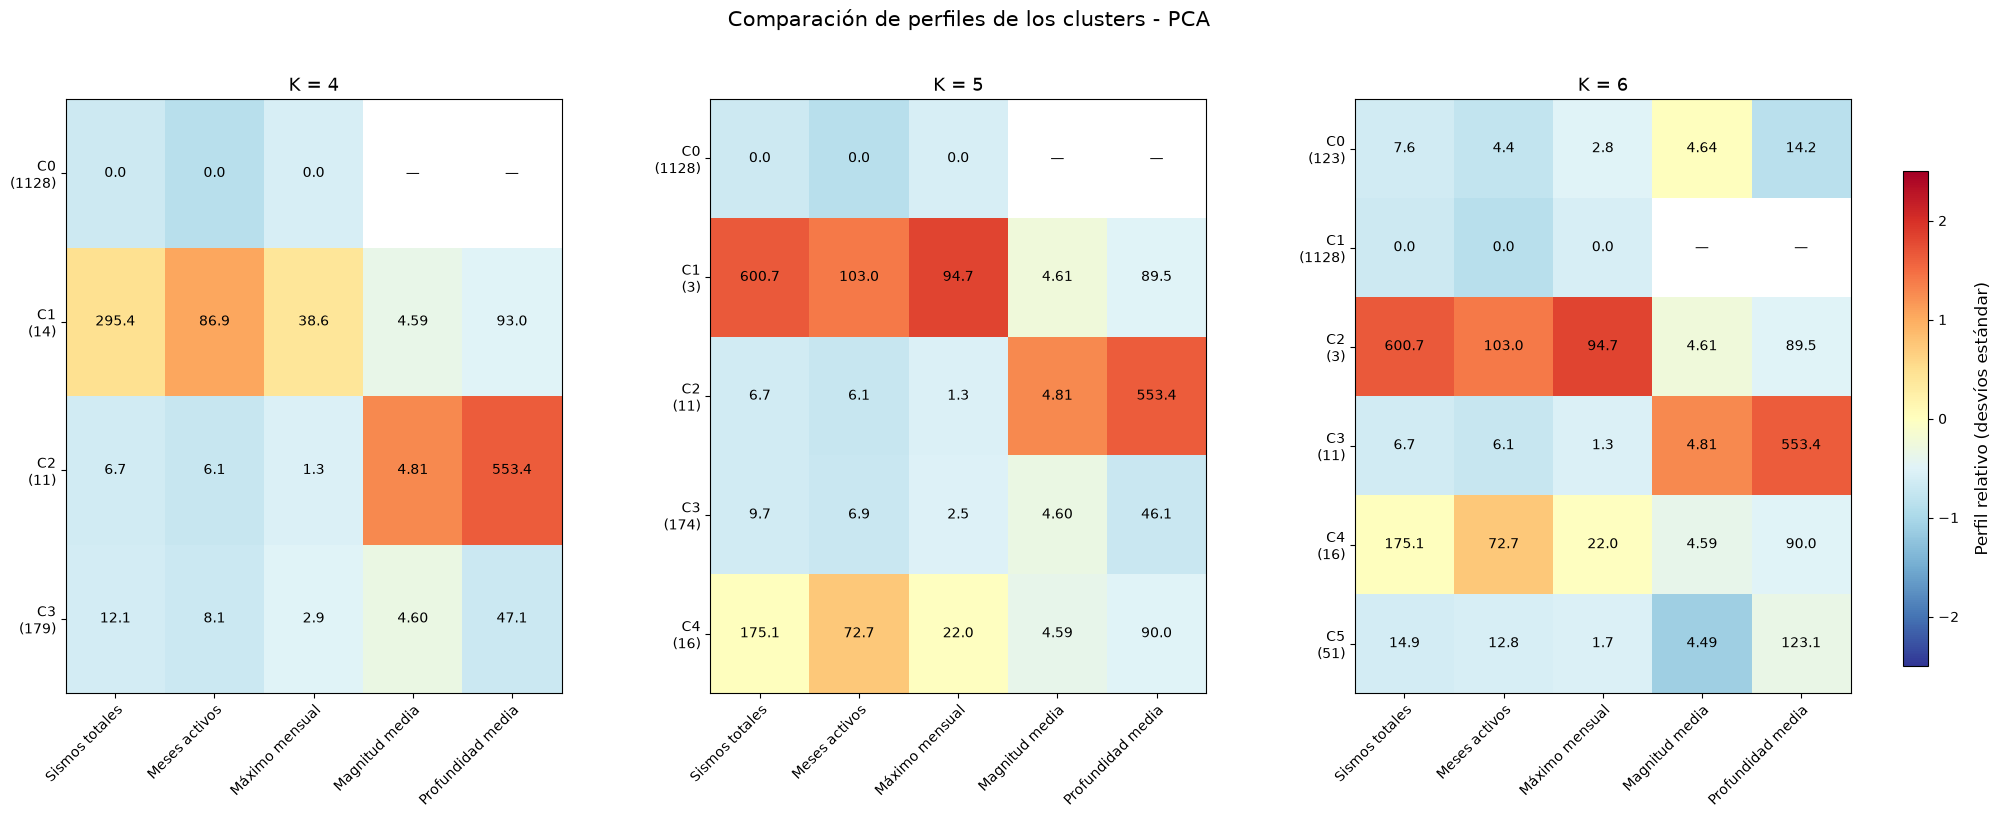

In [41]:
# ============================================================
# 6.8. VISUALIZACIÓN COMPARATIVA DE PERFILES - PCA
# ============================================================

# Variables que vamos a comparar
variables_perfil = [
    "sismos_totales_media",
    "meses_activos_media",
    "maximo_mensual_media",
    "magnitud_media",
    "profundidad_media"
]

nombres_variables = [
    "Sismos totales",
    "Meses activos",
    "Máximo mensual",
    "Magnitud media",
    "Profundidad media"
]


# ------------------------------------------------------------
# 6.8.1. GRÁFICO DE CANTIDAD DE CELDAS POR CLUSTER
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    sharey=False
)

for ax, k in zip(axes, [4, 5, 6]):

    datos_k = perfiles_comparacion_pca[
        perfiles_comparacion_pca["K"] == k
    ]

    barras = ax.bar(
        datos_k["cluster"].astype(str),
        datos_k["cantidad_celdas"],
        color="#0072B2",
        edgecolor="black",
        linewidth=0.7
    )

    ax.bar_label(
        barras,
        padding=3,
        fontsize=9
    )

    ax.set_title(f"K = {k}", fontsize=13)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Cantidad de celdas")
    ax.set_ylim(
        0,
        datos_k["cantidad_celdas"].max() * 1.15
    )

fig.suptitle(
    "Cantidad de celdas por cluster - PCA",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6.8.2. PREPARAR PERFILES PARA EL MAPA DE CALOR
# ------------------------------------------------------------

# Utilizar los mismos parámetros de estandarización
# que en el modelo original para facilitar la comparación.

medias_pca = perfiles_comparacion_pca[variables_perfil]

perfiles_estandarizados_pca = (
    medias_pca - media_global
) / desvio_global


# ------------------------------------------------------------
# 6.8.3. MAPAS DE CALOR PARA K=4, K=5 Y K=6
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(21, 9)
)

for ax, k in zip(axes, [4, 5, 6]):

    indices = perfiles_comparacion_pca.index[
        perfiles_comparacion_pca["K"] == k
    ]

    datos_k = perfiles_comparacion_pca.loc[indices]
    matriz_k = perfiles_estandarizados_pca.loc[indices]

    imagen = ax.imshow(
        matriz_k.values,
        cmap="RdYlBu_r",
        aspect="auto",
        vmin=-2.5,
        vmax=2.5
    )

    # Etiquetas de clusters en dos líneas
    etiquetas_y = [
        f"C{int(fila.cluster)}\n({int(fila.cantidad_celdas)})"
        for fila in datos_k.itertuples()
    ]

    ax.set_yticks(range(len(etiquetas_y)))
    ax.set_yticklabels(
        etiquetas_y,
        fontsize=10
    )

    # Etiquetas de variables en diagonal
    ax.set_xticks(range(len(nombres_variables)))
    ax.set_xticklabels(
        nombres_variables,
        rotation=45,
        ha="right",
        rotation_mode="anchor",
        fontsize=10
    )

    ax.set_title(f"K = {k}", fontsize=13)

    # Valores originales dentro de cada celda
    for i, (_, fila) in enumerate(datos_k.iterrows()):

        for j, variable in enumerate(variables_perfil):

            valor = fila[variable]

            if pd.isna(valor):
                texto = "—"
            elif variable == "magnitud_media":
                texto = f"{valor:.2f}"
            else:
                texto = f"{valor:.1f}"

            ax.text(
                j,
                i,
                texto,
                ha="center",
                va="center",
                fontsize=10,
                color="black"
            )


# Barra de color en un eje independiente
barra_ax = fig.add_axes([0.945, 0.25, 0.012, 0.55])

barra = fig.colorbar(
    imagen,
    cax=barra_ax
)

barra.set_label(
    "Perfil relativo (desvíos estándar)",
    fontsize=12,
    labelpad=10
)

fig.suptitle(
    "Comparación de perfiles de los clusters - PCA",
    fontsize=15
)

plt.subplots_adjust(
    left=0.07,
    right=0.92,
    bottom=0.22,
    top=0.88,
    wspace=0.30
)

plt.show()

In [42]:
# ============================================================
# 6.9. COMPARACIÓN DE ASIGNACIONES - PCA
# ============================================================

# Construir tabla de asignaciones
comparacion_asignaciones_pca = resumen_zonas[
    ["zona_id", "cantidad_total", "meses_activos", "maximo_mensual"]
].copy()

comparacion_asignaciones_pca["cluster_k4"] = modelos_kmeans_pca[4].labels_
comparacion_asignaciones_pca["cluster_k5"] = modelos_kmeans_pca[5].labels_
comparacion_asignaciones_pca["cluster_k6"] = modelos_kmeans_pca[6].labels_


# ------------------------------------------------------------
# 6.9.1. COMPARAR ASIGNACIONES ENTRE K=4 Y K=5
# ------------------------------------------------------------

print("DISTRIBUCIÓN DE CELDAS: K=4 FRENTE A K=5 (PCA)")

display(
    pd.crosstab(
        comparacion_asignaciones_pca["cluster_k4"],
        comparacion_asignaciones_pca["cluster_k5"],
        margins=True
    )
)


# ------------------------------------------------------------
# 6.9.2. COMPARAR ASIGNACIONES ENTRE K=4 Y K=6
# ------------------------------------------------------------

print("\nDISTRIBUCIÓN DE CELDAS: K=4 FRENTE A K=6 (PCA)")

display(
    pd.crosstab(
        comparacion_asignaciones_pca["cluster_k4"],
        comparacion_asignaciones_pca["cluster_k6"],
        margins=True
    )
)


# ------------------------------------------------------------
# 6.9.3. COMPARAR ASIGNACIONES ENTRE K=5 Y K=6
# ------------------------------------------------------------

print("\nDISTRIBUCIÓN DE CELDAS: K=5 FRENTE A K=6 (PCA)")

display(
    pd.crosstab(
        comparacion_asignaciones_pca["cluster_k5"],
        comparacion_asignaciones_pca["cluster_k6"],
        margins=True
    )
)

DISTRIBUCIÓN DE CELDAS: K=4 FRENTE A K=5 (PCA)


cluster_k5,0,1,2,3,4,All
cluster_k4,,,,,,
0,1128,0,0,0,0,1128
1,0,3,0,0,11,14
2,0,0,11,0,0,11
3,0,0,0,174,5,179
All,1128,3,11,174,16,1332



DISTRIBUCIÓN DE CELDAS: K=4 FRENTE A K=6 (PCA)


cluster_k6,0,1,2,3,4,5,All
cluster_k4,,,,,,,
0,0,1128,0,0,0,0,1128
1,0,0,3,0,11,0,14
2,0,0,0,11,0,0,11
3,123,0,0,0,5,51,179
All,123,1128,3,11,16,51,1332



DISTRIBUCIÓN DE CELDAS: K=5 FRENTE A K=6 (PCA)


cluster_k6,0,1,2,3,4,5,All
cluster_k5,,,,,,,
0,0,1128,0,0,0,0,1128
1,0,0,3,0,0,0,3
2,0,0,0,11,0,0,11
3,123,0,0,0,0,51,174
4,0,0,0,0,16,0,16
All,123,1128,3,11,16,51,1332


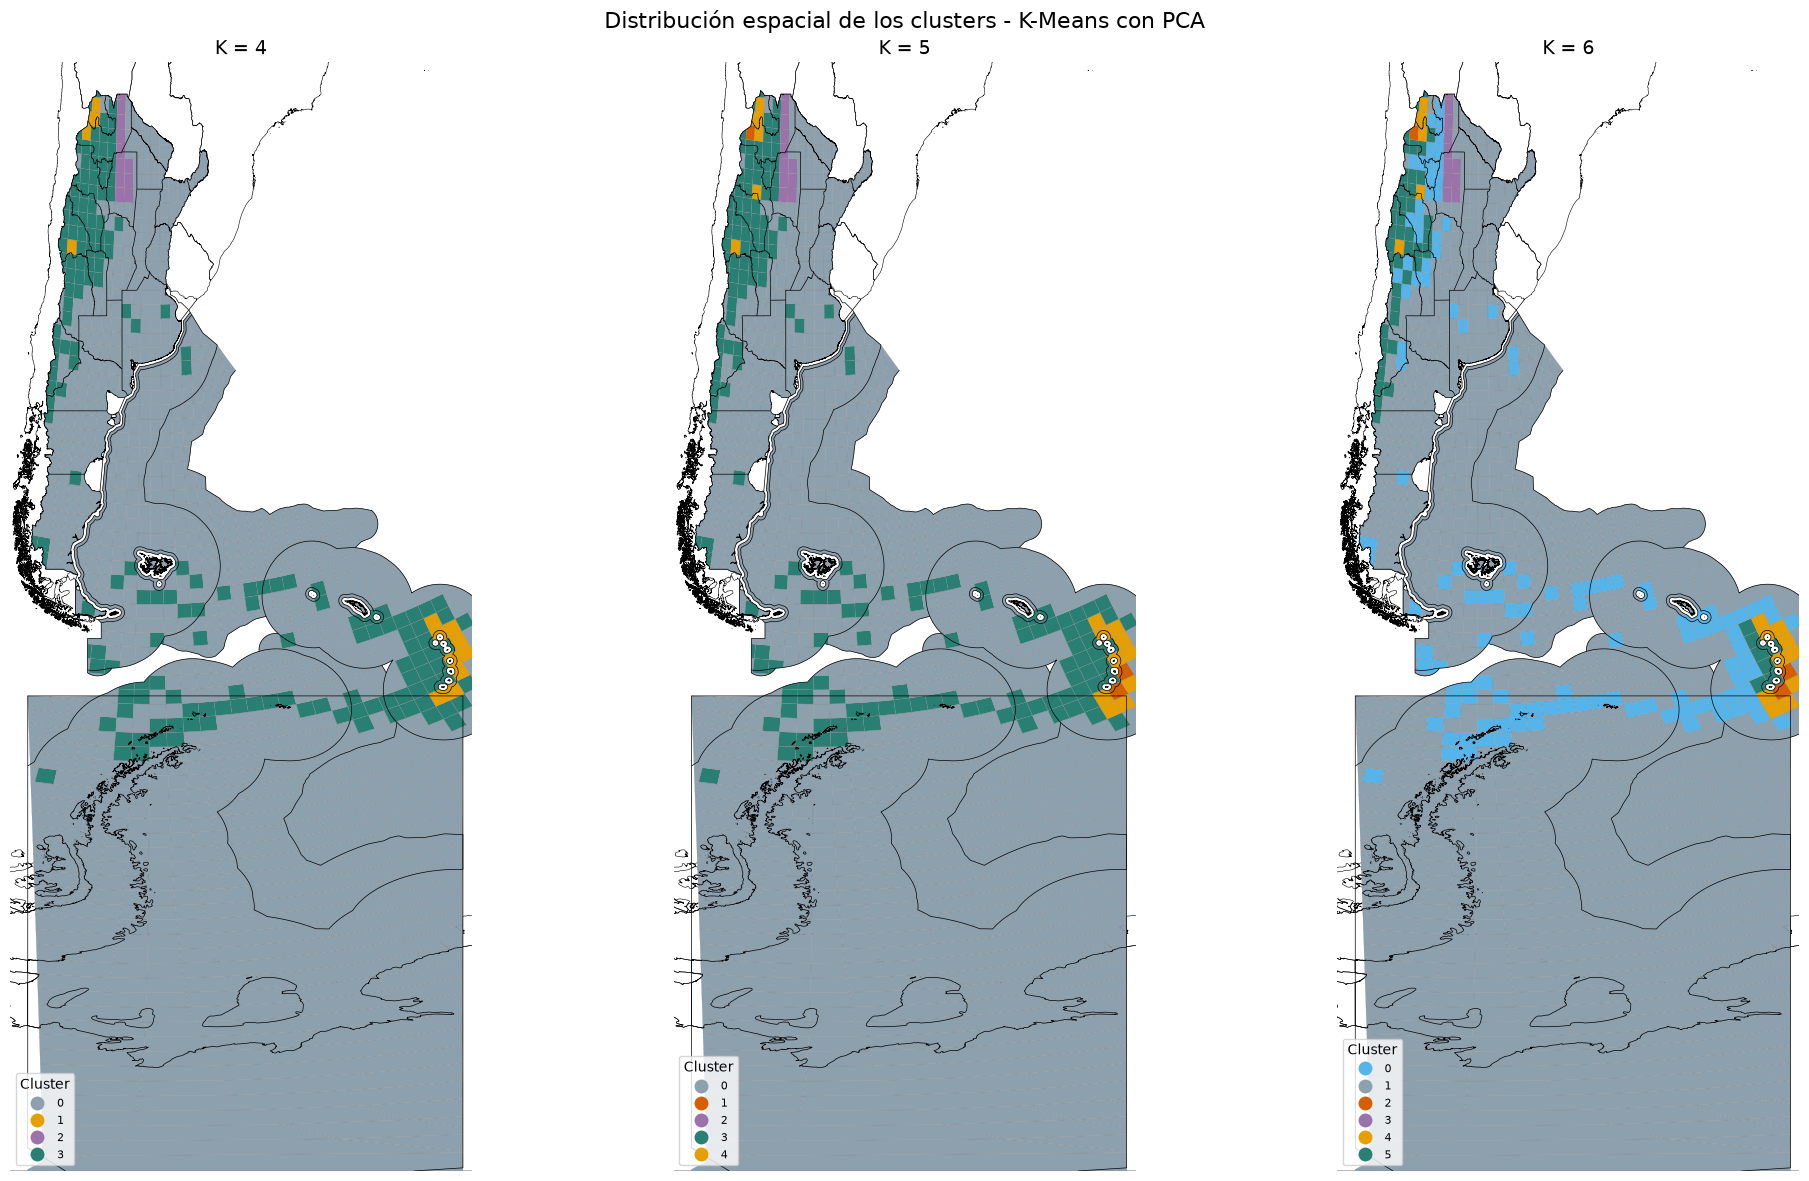

In [43]:
# ============================================================
# 6.10. COMPARACIÓN ESPACIAL - MODELO CON PCA
# ============================================================

# Paletas coherentes según los perfiles de cada cluster
paletas_pca = {
    4: [
        "#8DA0AE",  # C0: Sin actividad
        "#E69F00",  # C1: Actividad elevada y sostenida
        "#9B72AA",  # C2: Actividad poco frecuente y profunda
        "#2A7F75"   # C3: Actividad baja
    ],

    5: [
        "#8DA0AE",  # C0: Sin actividad
        "#D55E00",  # C1: Actividad extremadamente elevada
        "#9B72AA",  # C2: Actividad poco frecuente y profunda
        "#2A7F75",  # C3: Actividad baja
        "#E69F00"   # C4: Actividad elevada y persistente
    ],

    6: [
        "#56B4E9",  # C0: Actividad baja-moderada, relativamente profunda
        "#8DA0AE",  # C1: Sin actividad
        "#D55E00",  # C2: Actividad extremadamente elevada
        "#9B72AA",  # C3: Actividad muy profunda
        "#E69F00",  # C4: Actividad elevada y persistente
        "#2A7F75"   # C5: Actividad baja, predominantemente superficial
    ]
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(21, 12)
)

for ax, k in zip(axes, [4, 5, 6]):

    # Asignar etiquetas del modelo PCA a cada celda
    asignaciones_k = pd.DataFrame({
        "zona_id": resumen_zonas["zona_id"].to_numpy(),
        "cluster": modelos_kmeans_pca[k].labels_
    })

    grilla_k = grilla_recortada.merge(
        asignaciones_k,
        on="zona_id",
        how="left"
    )

    # Referencias geográficas
    ign_sudam.plot(
        ax=ax,
        facecolor="none",
        edgecolor="black",
        linewidth=0.4
    )

    # Grilla coloreada según cluster
    grilla_k.to_crs("EPSG:4326").plot(
        column="cluster",
        categorical=True,
        cmap=ListedColormap(paletas_pca[k]),
        legend=True,
        ax=ax,
        edgecolor="gray",
        linewidth=0.15,
        legend_kwds={
            "title": "Cluster",
            "loc": "lower left",
            "fontsize": 8
        }
    )

    ign_arg.plot(
        ax=ax,
        color="black",
        linewidth=0.5
    )

    ax.set_xlim(-76, -24)
    ax.set_ylim(-90, -20)
    ax.set_title(f"K = {k}", fontsize=14)
    ax.set_axis_off()

fig.suptitle(
    "Distribución espacial de los clusters - K-Means con PCA",
    fontsize=16
)

plt.tight_layout()
plt.show()

##### SÍNTESIS Y JUSTIFICACIÓN DE LA SELECCIÓN DEL MODELO (PCA)

La comparación de las distintas soluciones permitió identificar diferencias en el nivel de detalle que aporta cada modelo:

| Modelo | Aporte principal |
|---|---|
| **Original K=4** | Distingue cuatro perfiles generales de actividad sísmica. |
| **PCA K=4** | Reproduce los cuatro perfiles generales de K=4 original, sin aportar una diferenciación adicional relevante. |
| **Original K=5** | Separa las tres celdas de actividad extrema, pero no aporta una diferenciación sustancial de los perfiles restantes respecto de K=4. |
| **PCA K=5** | Mantiene los cinco perfiles generales de K=5 original, sin incorporar una diferenciación sustancial nueva. |
| **Original K=6** | Divide el grupo de actividad extrema, pero no genera una diferenciación nueva relevante en los grupos de actividad baja. |
| **PCA K=6** | Conserva el grupo de tres celdas de actividad extrema y, además, divide el grupo de baja actividad en dos perfiles diferenciados principalmente por la profundidad. |

El resultado más relevante se observa al comparar K=5 con K=6 mediante PCA. En esta última solución, el grupo de 174 celdas de actividad baja identificado en K=5 se divide en dos grupos con características diferenciadas:

- **51 celdas:** actividad baja-moderada, relativamente profunda, con una profundidad media de 123,1 km.
- **123 celdas:** actividad baja, predominantemente superficial, con una profundidad media de 14,2 km.

Esta separación permite identificar una estructura que no aparece en las soluciones anteriores y agrega una dimensión de análisis que no aportaban K=4, K=5 ni K=6 sobre las variables originales.

Por lo tanto, se selecciona **K=6 con PCA** como modelo de referencia para la caracterización detallada de los patrones espaciales de actividad sísmica. Esta elección se fundamenta en el mayor nivel de diferenciación que permite obtener, sin perder de vista que K=4 sobre las variables originales ofrece una clasificación más compacta de los perfiles generales.

### 7. Caracterización y evaluación de los clusters

In [44]:
# 7.1. Evaluación de estabilidad

# Ejecutar las evaluaciones para los dos modelos

mascara_activas = (
    resumen_zonas["cantidad_total"].to_numpy() > 0
)

# ejecutamos las cuatro evaluaciones:

# 7.1.1. K-Means original: K=4
estabilidad_original_inicializaciones = evaluar_inicializaciones(
    datos_escalados,
    k=4,
    mascara_activas=mascara_activas
)

estabilidad_original_submuestras = evaluar_submuestras(
    datos_clustering,
    k=4,
    mascara_activas=mascara_activas,
    usar_pca=False
)


# 7.1.2. K-Means con PCA: K=6
estabilidad_pca_inicializaciones = evaluar_inicializaciones(
    datos_pca,
    k=6,
    mascara_activas=mascara_activas
)

estabilidad_pca_submuestras = evaluar_submuestras(
    datos_clustering,
    k=6,
    mascara_activas=mascara_activas,
    usar_pca=True,
    n_componentes=3
)

In [45]:
# 7.2. Comparación de resultados de estabilidad

resultados_estabilidad = []

evaluaciones = {
    "Original K=4 - Inicializaciones": estabilidad_original_inicializaciones,
    "Original K=4 - Submuestras": estabilidad_original_submuestras,
    "PCA K=6 - Inicializaciones": estabilidad_pca_inicializaciones,
    "PCA K=6 - Submuestras": estabilidad_pca_submuestras
}

for nombre, resultado in evaluaciones.items():

    for conjunto, metricas in resultado.items():

        fila = {
            "modelo": nombre,
            "conjunto": conjunto
        }

        fila.update(metricas)

        resultados_estabilidad.append(fila)

tabla_estabilidad = pd.DataFrame(resultados_estabilidad)

display(
    tabla_estabilidad.round(4)
)

,modelo,conjunto,ARI_promedio,ARI_desvio,ARI_minimo,ARI_maximo
0,Original K=4 - Inicializaciones,Todas las celdas,1.0000,0.0000,1.0000,1.0
1,Original K=4 - Inicializaciones,Solo celdas activas,1.0000,0.0000,1.0000,1.0
2,Original K=4 - Submuestras,Todas las celdas,0.9984,0.0023,0.9917,1.0
3,Original K=4 - Submuestras,Solo celdas activas,0.9237,0.1171,0.5648,1.0
4,PCA K=6 - Inicializaciones,Todas las celdas,1.0000,0.0000,0.9998,1.0
5,PCA K=6 - Inicializaciones,Solo celdas activas,0.9996,0.0016,0.9935,1.0
6,PCA K=6 - Submuestras,Todas las celdas,0.9914,0.0086,0.9810,1.0
7,PCA K=6 - Submuestras,Solo celdas activas,0.7191,0.2773,0.3804,1.0


##### Interpretación de la estabilidad de los modelos

_La evaluación mediante el índice Adjusted Rand (ARI) muestra una estabilidad muy elevada en ambos modelos frente a distintas inicializaciones, con valores promedio cercanos a 1._

_Sin embargo, al evaluar distintas submuestras y considerar únicamente las 204 celdas activas, se observan diferencias importantes. El modelo original K=4 obtuvo un ARI promedio de 0,92, mientras que K=6 con PCA alcanzó 0,71, con una mayor variabilidad entre las agrupaciones obtenidas._

_Al considerar las 1332 celdas, ambos modelos presentan valores de estabilidad superiores a 0,99. Esta diferencia respecto de los resultados en celdas activas evidencia la influencia de las 1128 celdas sin actividad sísmica en la evaluación global._

_En conjunto, los resultados indican que K=4 presenta una mayor estabilidad ante cambios en las muestras de entrenamiento, mientras que K=6 con PCA ofrece una clasificación más detallada de los perfiles de actividad, aunque con mayor sensibilidad en las asignaciones de las celdas activas._

In [46]:
# ============================================================
# 7.3. EVALUACIÓN COMPLEMENTARIA: K=4 CON PCA
# ============================================================

# Estabilidad ante distintas inicializaciones
estabilidad_pca_k4_inicializaciones = evaluar_inicializaciones(
    datos_pca,
    k=4,
    mascara_activas=mascara_activas
)

# Estabilidad ante distintas submuestras
estabilidad_pca_k4_submuestras = evaluar_submuestras(
    datos_clustering,
    k=4,
    mascara_activas=mascara_activas,
    usar_pca=True,
    n_componentes=3
)

In [47]:
# ============================================================
# 7.4. COMPARACIÓN DE ESTABILIDAD: PCA K=4 VS. K=6
# ============================================================

resultados_estabilidad_pca = []

evaluaciones_pca = {
    "PCA K=4 - Inicializaciones": estabilidad_pca_k4_inicializaciones,
    "PCA K=4 - Submuestras": estabilidad_pca_k4_submuestras,
    "PCA K=6 - Inicializaciones": estabilidad_pca_inicializaciones,
    "PCA K=6 - Submuestras": estabilidad_pca_submuestras
}

for nombre, resultado in evaluaciones_pca.items():

    for conjunto, metricas in resultado.items():

        fila = {
            "modelo": nombre,
            "conjunto": conjunto
        }

        fila.update(metricas)

        resultados_estabilidad_pca.append(fila)

tabla_estabilidad_pca = pd.DataFrame(resultados_estabilidad_pca)

display(
    tabla_estabilidad_pca.round(4)
)

,modelo,conjunto,ARI_promedio,ARI_desvio,ARI_minimo,ARI_maximo
0,PCA K=4 - Inicializaciones,Todas las celdas,1.0000,0.0000,1.0000,1.0
1,PCA K=4 - Inicializaciones,Solo celdas activas,1.0000,0.0000,1.0000,1.0
2,PCA K=4 - Submuestras,Todas las celdas,0.9989,0.0011,0.9955,1.0
3,PCA K=4 - Submuestras,Solo celdas activas,0.9496,0.0538,0.7862,1.0
4,PCA K=6 - Inicializaciones,Todas las celdas,1.0000,0.0000,0.9998,1.0
5,PCA K=6 - Inicializaciones,Solo celdas activas,0.9996,0.0016,0.9935,1.0
6,PCA K=6 - Submuestras,Todas las celdas,0.9914,0.0086,0.9810,1.0
7,PCA K=6 - Submuestras,Solo celdas activas,0.7191,0.2773,0.3804,1.0


##### Comparación de estabilidad entre modelos PCA

_La comparación entre ambos modelos en el espacio PCA muestra que la incorporación de seis clusters no modifica sustancialmente la estabilidad frente a distintas inicializaciones. Sin embargo, ante cambios en las muestras de entrenamiento, K=4 presenta un ARI promedio de 0,94 en las celdas activas, frente a 0,71 para K=6._

_Esto indica que el aumento en el nivel de detalle de la clasificación se acompaña de una mayor sensibilidad de las asignaciones. No obstante, K=6 permite diferenciar perfiles de actividad baja según sus características de profundidad, una separación que no se obtiene con K=4._

In [48]:
# ============================================================
# 7.5. AJUSTE DE LOS MODELOS SELECCIONADOS
# ============================================================

# 7.5.1. Modelo seleccionado: K=4 (datos originales)
modelo_k4 = KMeans(
    n_clusters=4,
    n_init=10,
    random_state=42
)

etiquetas_k4 = pd.Series(
    modelo_k4.fit_predict(datos_escalados),
    index=datos_escalados.index,
    name="cluster"
)

# 7.5.2. Modelo seleccionado: K=6 (PCA)
modelo_k6_pca = KMeans(
    n_clusters=6,
    n_init=10,
    random_state=42
)

etiquetas_k6_pca = pd.Series(
    modelo_k6_pca.fit_predict(datos_pca),
    index=datos_pca.index,
    name="cluster"
)

# Resumen de los modelos ajustados
print("Modelo original K=4:", modelo_k4)
print("Random state:", modelo_k4.random_state)
print("Cantidad de clusters:", modelo_k4.n_clusters)

print("\nModelo PCA K=6:", modelo_k6_pca)
print("Random state:", modelo_k6_pca.random_state)
print("Cantidad de clusters:", modelo_k6_pca.n_clusters)

Modelo original K=4: KMeans(n_clusters=4, n_init=10, random_state=42)
Random state: 42
Cantidad de clusters: 4

Modelo PCA K=6: KMeans(n_clusters=6, n_init=10, random_state=42)
Random state: 42
Cantidad de clusters: 6


In [49]:
# ============================================================
# 7.6.1. ASIGNACIÓN Y CARACTERIZACIÓN DE CLUSTERS - K=4
# ============================================================

# Asignar clusters del modelo definitivo
perfil_k4 = resumen_zonas.copy()
perfil_k4["cluster"] = etiquetas_k4

# Caracterización de los clusters
resumen_perfil_k4 = perfil_k4.groupby("cluster").agg(
    cantidad_celdas=("zona_id", "count"),
    sismos_promedio=("cantidad_total", "mean"),
    sismos_mediana=("cantidad_total", "median"),
    meses_activos_promedio=("meses_activos", "mean"),
    maximo_mensual_promedio=("maximo_mensual", "mean"),
    magnitud_media=("magnitud_media", "mean"),
    profundidad_media=("profundidad_media", "mean")
)

display(resumen_perfil_k4.round(2))

,cantidad_celdas,sismos_promedio,sismos_mediana,meses_activos_promedio,maximo_mensual_promedio,magnitud_media,profundidad_media
cluster,,,,,,,
0,1128,0.00,0.0,0.00,0.00,NaN,NaN
1,14,295.36,217.5,86.93,38.64,4.59,93.05
2,11,6.73,7.0,6.09,1.27,4.81,553.37
3,179,12.08,4.0,8.10,2.93,4.60,47.10


In [50]:
# ============================================================
# 7.6.2. NORMALIZACIÓN DE ETIQUETAS SEGÚN LOS PERFILES - K=4
# ============================================================

# Identificar el cluster sin actividad sísmica
cluster_sin_actividad = resumen_perfil_k4.index[
    resumen_perfil_k4["sismos_promedio"] == 0
][0]

# Identificar el cluster con mayor actividad
cluster_alta_actividad = (
    resumen_perfil_k4["sismos_promedio"].idxmax()
)

# Identificar los clusters restantes
clusters_restantes = [
    c for c in resumen_perfil_k4.index
    if c not in [cluster_sin_actividad, cluster_alta_actividad]
]

# Identificar el cluster de mayor profundidad
cluster_profundo = (
    resumen_perfil_k4.loc[
        clusters_restantes, "profundidad_media"
    ].idxmax()
)

# Identificar el cluster restante
cluster_baja_actividad = [
    c for c in clusters_restantes
    if c != cluster_profundo
][0]

# Crear correspondencia de etiquetas
mapa_clusters_k4 = {
    cluster_sin_actividad: 0,
    cluster_alta_actividad: 1,
    cluster_profundo: 2,
    cluster_baja_actividad: 3
}

# Incorporar las etiquetas normalizadas
perfil_k4["cluster_normalizado"] = (
    perfil_k4["cluster"].map(mapa_clusters_k4)
)

print("Correspondencia entre etiquetas originales y normalizadas:")
display(
    pd.DataFrame(
        list(mapa_clusters_k4.items()),
        columns=["Cluster original", "Cluster normalizado"]
    ).sort_values("Cluster normalizado")
)

print("\nCantidad de celdas por cluster normalizado:")
display(
    perfil_k4["cluster_normalizado"]
    .value_counts()
    .sort_index()
)

Correspondencia entre etiquetas originales y normalizadas:


,Cluster original,Cluster normalizado
0,0,0
1,1,1
2,2,2
3,3,3



Cantidad de celdas por cluster normalizado:


cluster_normalizado
0    1128
1      14
2      11
3     179
Name: count, dtype: int64

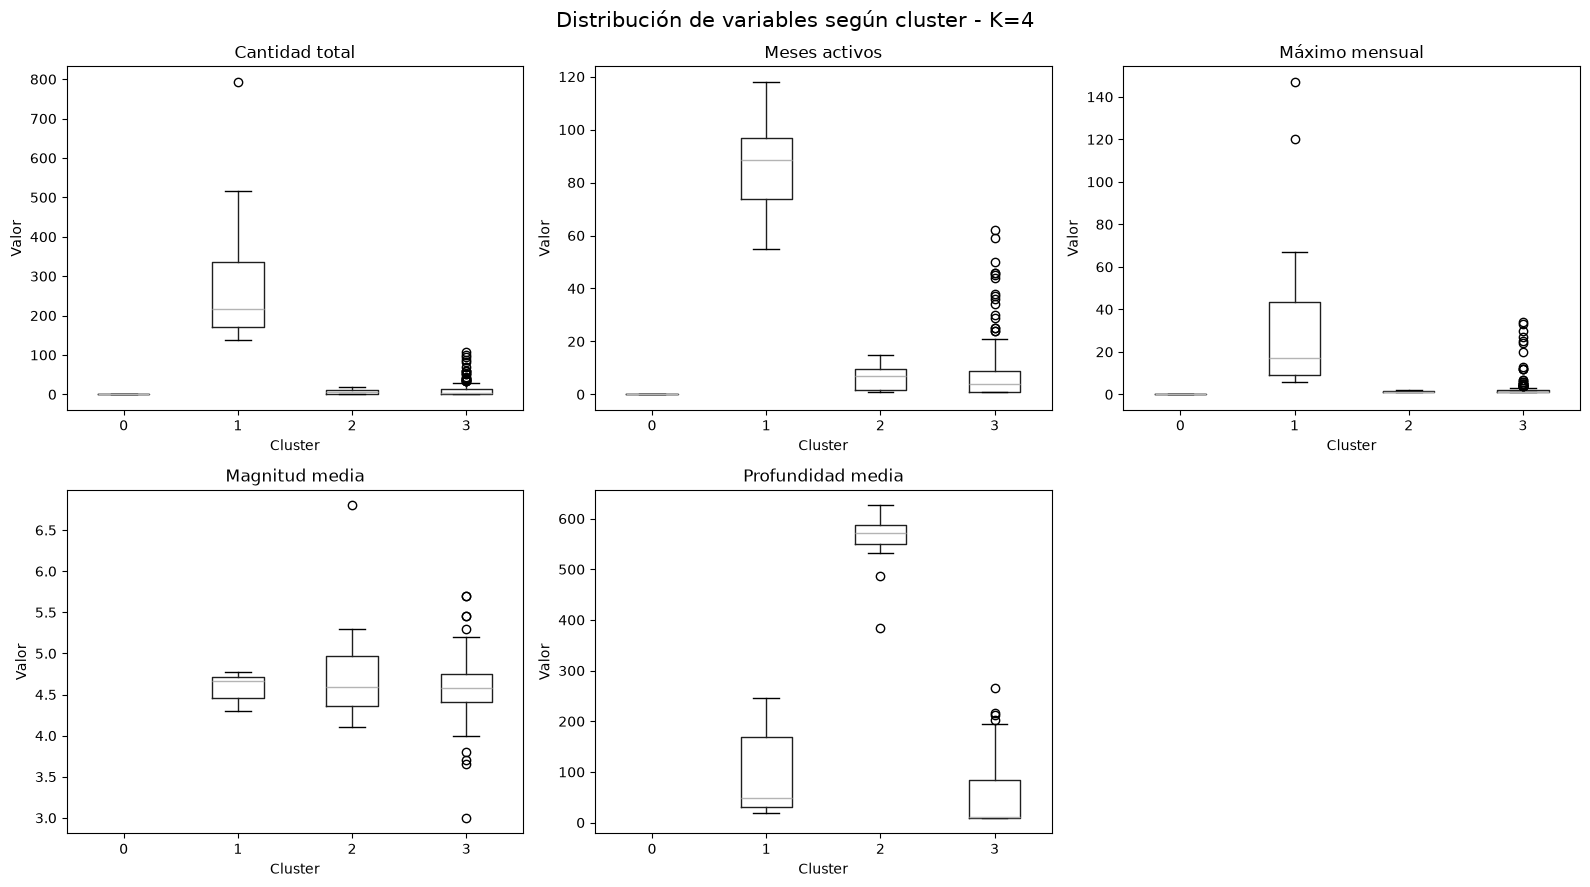

In [51]:
# ============================================================
# 7.6.3. DISTRIBUCIÓN DE VARIABLES SEGÚN CLUSTER - K=4
# ============================================================

variables_graficos = [
    "cantidad_total",
    "meses_activos",
    "maximo_mensual",
    "magnitud_media",
    "profundidad_media"
]

nombres_variables = {
    "cantidad_total": "Cantidad total",
    "meses_activos": "Meses activos",
    "maximo_mensual": "Máximo mensual",
    "magnitud_media": "Magnitud media",
    "profundidad_media": "Profundidad media"
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, variable in enumerate(variables_graficos):
    perfil_k4.boxplot(
        column=variable,
        by="cluster_normalizado",
        ax=axes[i],
        grid=False
    )
    axes[i].set_title(nombres_variables[variable])
    axes[i].set_xlabel("Cluster")
    axes[i].set_ylabel("Valor")

fig.delaxes(axes[-1])

fig.suptitle(
    "Distribución de variables según cluster - K=4",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Interpretación de los clusters

La agrupación obtenida permite distinguir cuatro perfiles de celdas según sus características de actividad sísmica:

- **Cluster 0 – Sin actividad:** reúne celdas sin eventos sísmicos registrados durante el período de estudio.
- **Cluster 1 – Actividad elevada y sostenida:** agrupa celdas con una cantidad muy alta de sismos, numerosos meses activos y máximos mensuales elevados.
- **Cluster 2 – Actividad poco frecuente y profunda:** reúne celdas con pocos eventos y una profundidad media considerablemente mayor que la del resto de los grupos.
- **Cluster 3 – Actividad baja:** representa celdas con una cantidad reducida de eventos y pocos meses con actividad sísmica.

Estos perfiles permiten diferenciar distintos patrones espaciales de actividad sísmica, que se analizarán a continuación mediante su distribución geográfica.

In [52]:
# ============================================================
# 7.7. ASIGNACIÓN Y CARACTERIZACIÓN DE CLUSTERS - K=6 (PCA)
# ============================================================

# 7.7.1. Caracterización de los clusters.

# Asignar clusters del modelo definitivo
perfil_k6 = resumen_zonas.copy()
perfil_k6["cluster"] = etiquetas_k6_pca

# Caracterización de los clusters
resumen_perfil_k6 = perfil_k6.groupby("cluster").agg(
    cantidad_celdas=("zona_id", "count"),
    sismos_promedio=("cantidad_total", "mean"),
    sismos_mediana=("cantidad_total", "median"),
    meses_activos_promedio=("meses_activos", "mean"),
    maximo_mensual_promedio=("maximo_mensual", "mean"),
    magnitud_media=("magnitud_media", "mean"),
    profundidad_media=("profundidad_media", "mean")
)

display(resumen_perfil_k6.round(2))

,cantidad_celdas,sismos_promedio,sismos_mediana,meses_activos_promedio,maximo_mensual_promedio,magnitud_media,profundidad_media
cluster,,,,,,,
0,123,7.61,2.0,4.41,2.80,4.64,14.20
1,1128,0.00,0.0,0.00,0.00,NaN,NaN
2,3,600.67,515.0,103.00,94.67,4.61,89.48
3,11,6.73,7.0,6.09,1.27,4.81,553.37
4,16,175.06,161.5,72.69,22.00,4.59,89.98
5,51,14.88,8.0,12.80,1.67,4.49,123.14


In [53]:
# ==================================================================
# 7.7.2. RANGOS DE ACTIVIDAD Y PROFUNDIDAD POR CLUSTER - K=6 (PCA)
# ==================================================================

rangos_k6 = perfil_k6.groupby("cluster").agg(
    profundidad_min=("profundidad_media", "min"),
    profundidad_max=("profundidad_media", "max"),
    sismos_min=("cantidad_total", "min"),
    sismos_max=("cantidad_total", "max")
)

display(rangos_k6.round(2))

,profundidad_min,profundidad_max,sismos_min,sismos_max
cluster,,,,
0,9.35,68.26,1,60
1,NaN,NaN,0,0
2,37.50,190.83,494,793
3,384.63,626.01,1,19
4,10.84,245.50,81,347
5,15.42,264.94,1,69


In [ ]:
# ===============================================================
# 7.7.3. NORMALIZACIÓN DE ETIQUETAS SEGÚN LOS PERFILES - K=6 PCA
# ===============================================================

# Identificar los clusters según sus perfiles
mapa_clusters_k6 = {
    1: 0,  # Sin actividad
    2: 1,  # Actividad extremadamente elevada
    4: 2,  # Actividad elevada y persistente
    3: 3,  # Actividad muy profunda
    0: 4,  # Actividad baja, predominantemente superficial
    5: 5   # Actividad baja-moderada, relativamente profunda
}

# Incorporar las etiquetas normalizadas
perfil_k6["cluster_normalizado"] = (
    perfil_k6["cluster"].map(mapa_clusters_k6)
)

# Correspondencia entre etiquetas originales y normalizadas
print("Correspondencia entre etiquetas originales y normalizadas:")
display(
    pd.DataFrame(
        list(mapa_clusters_k6.items()),
        columns=["Cluster original", "Cluster normalizado"]
    ).sort_values("Cluster normalizado")
)

# Cantidad de celdas por cluster normalizado
print("\nCantidad de celdas por cluster normalizado:")
display(
    perfil_k6["cluster_normalizado"]
    .value_counts()
    .sort_index()
)

Correspondencia entre etiquetas originales y normalizadas:


,Cluster original,Cluster normalizado
0,1,0
1,2,1
2,4,2
3,3,3
4,0,4
5,5,5



Cantidad de celdas por cluster normalizado:


cluster_normalizado
0    1128
1       3
2      16
3      11
4     123
5      51
Name: count, dtype: int64

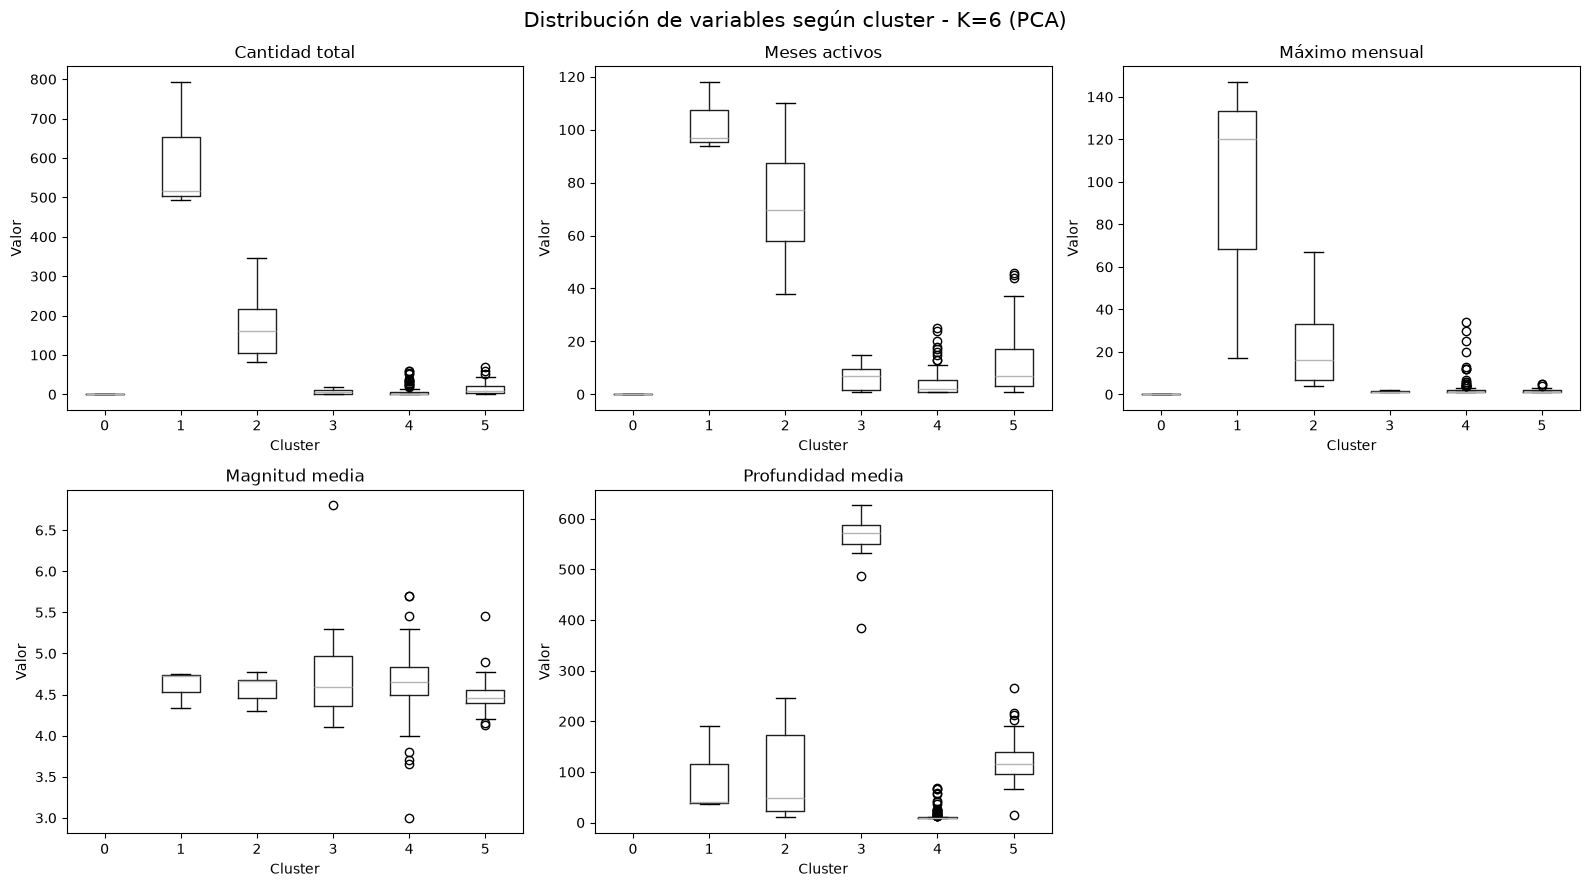

In [55]:
# ============================================================
# 7.7.4. DISTRIBUCIÓN DE VARIABLES SEGÚN CLUSTER - K=6 PCA
# ============================================================

variables_graficos = [
    "cantidad_total",
    "meses_activos",
    "maximo_mensual",
    "magnitud_media",
    "profundidad_media"
]

nombres_variables = {
    "cantidad_total": "Cantidad total",
    "meses_activos": "Meses activos",
    "maximo_mensual": "Máximo mensual",
    "magnitud_media": "Magnitud media",
    "profundidad_media": "Profundidad media"
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, variable in enumerate(variables_graficos):
    perfil_k6.boxplot(
        column=variable,
        by="cluster_normalizado",
        ax=axes[i],
        grid=False
    )
    axes[i].set_title(nombres_variables[variable])
    axes[i].set_xlabel("Cluster")
    axes[i].set_ylabel("Valor")

fig.delaxes(axes[-1])

fig.suptitle(
    "Distribución de variables según cluster - K=6 (PCA)",
    fontsize=15
)

plt.tight_layout()
plt.show()

##### Etiquetas descriptivas de los clusters - K=6 (PCA)

| Cluster original | Cluster normalizado | Perfil |
|:---:|:---:|---|
| C1 | C0 | Sin actividad |
| C2 | C1 | Actividad extremadamente elevada |
| C4 | C2 | Actividad elevada y persistente |
| C3 | C3 | Actividad muy profunda |
| C0 | C4 | Actividad baja, predominantemente superficial |
| C5 | C5 | Actividad baja-moderada, relativamente profunda |

_Las etiquetas se asignaron a partir de las características observadas en cada grupo, considerando principalmente la cantidad de sismos, la persistencia de la actividad y la profundidad media. Son denominaciones descriptivas utilizadas para facilitar la interpretación de los resultados y no representan categorías geológicas formales._

### 8. Distribución espacial de los modelos seleccionados

In [56]:
# ============================================================
# 8.1. INCORPORACIÓN DE LAS ETIQUETAS A LA GRILLA GEOGRÁFICA - K=4
# ============================================================

# Asociar las etiquetas normalizadas de K=4 a las geometrías
grilla_clusters_k4 = grilla_recortada.merge(
    perfil_k4[["zona_id", "cluster_normalizado"]],
    on="zona_id",
    how="left"
)

# Verificar la incorporación
print("Cantidad de celdas en la grilla:", len(grilla_clusters_k4))
print("Celdas con cluster asignado:", grilla_clusters_k4["cluster_normalizado"].notna().sum())
print("Celdas sin cluster asignado:", grilla_clusters_k4["cluster_normalizado"].isna().sum())

print("\nCantidad de celdas por cluster:")
display(
    grilla_clusters_k4["cluster_normalizado"]
    .value_counts()
    .sort_index()
)

Cantidad de celdas en la grilla: 1332
Celdas con cluster asignado: 1332
Celdas sin cluster asignado: 0

Cantidad de celdas por cluster:


cluster_normalizado
0    1128
1      14
2      11
3     179
Name: count, dtype: int64

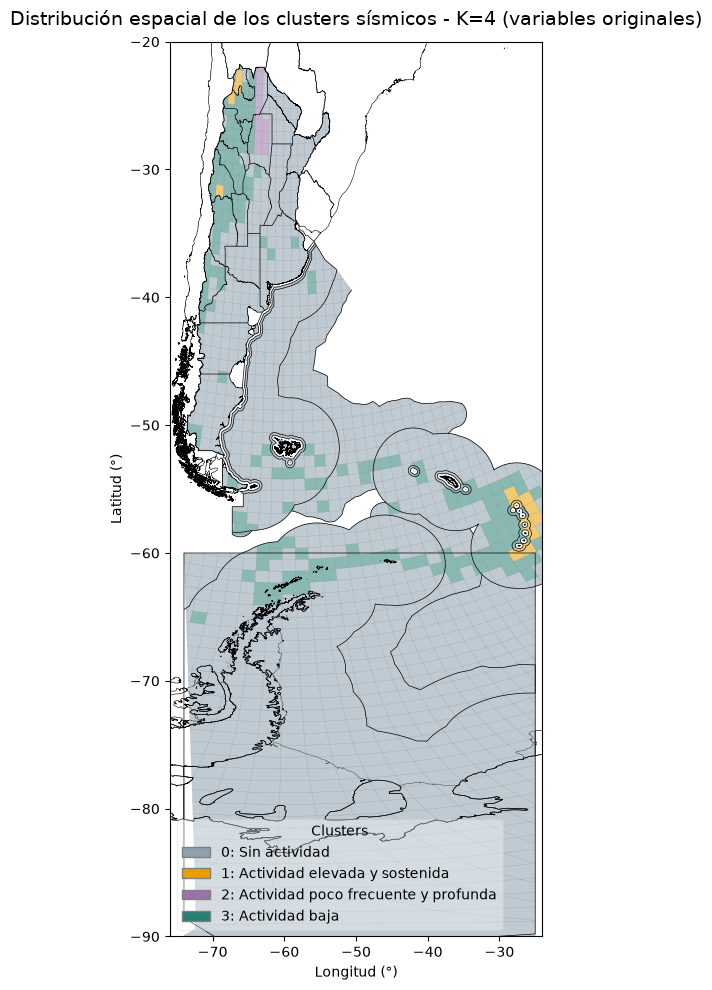

In [57]:
# ============================================================
# 8.2. VISUALIZACIÓN ESPACIAL DE LOS CLUSTERS
# ============================================================

# Definir colores para cada cluster
colores_clusters = ListedColormap([
    "#8DA0AE",  # Cluster 0: Sin actividad
    "#E69F00",  # Cluster 1: Actividad elevada y sostenida
    "#9B72AA",  # Cluster 2: Actividad poco frecuente y profunda
    "#2A7F75"   # Cluster 3: Actividad baja
])

# Crear figura
fig, ax = plt.subplots(figsize=(8, 10))

# Mapa de Sudamérica
ign_sudam.to_crs("EPSG:4326").plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.4
)

# Grilla coloreada según cluster
grilla_clusters_k4.to_crs("EPSG:4326").plot(
    column="cluster_normalizado",
    categorical=True,
    cmap=colores_clusters,
    ax=ax,
    edgecolor="gray",
    linewidth=0.15,
    alpha=0.55
)

# Límites de Argentina, incluida la silueta antártica
ign_arg.to_crs("EPSG:4326").plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.5
)

# Leyenda personalizada
elementos_leyenda = [
    Patch(facecolor="#8DA0AE", edgecolor="gray",
          label="0: Sin actividad"),
    Patch(facecolor="#E69F00", edgecolor="gray",
          label="1: Actividad elevada y sostenida"),
    Patch(facecolor="#9B72AA", edgecolor="gray",
          label="2: Actividad poco frecuente y profunda"),
    Patch(facecolor="#2A7F75", edgecolor="gray",
          label="3: Actividad baja")
]

ax.legend(
    handles=elementos_leyenda,
    title="Clusters",
    loc="lower left",
    frameon=True,
    framealpha=0.35
)

# Configuración del mapa
ax.set_xlim(-76, -24)
ax.set_ylim(-90, -20)

ax.set_xlabel("Longitud (°)")
ax.set_ylabel("Latitud (°)")

ax.set_title(
    "Distribución espacial de los clusters sísmicos - K=4 (variables originales)",
    fontsize=14,
    pad=12
)

plt.tight_layout()
plt.show()

In [58]:
# ============================================================
# 8.3. INCORPORACIÓN DE LAS ETIQUETAS A LA GRILLA GEOGRÁFICA - K=6 PCA
# ============================================================

# Asociar las etiquetas normalizadas de K=6 PCA a las geometrías
grilla_clusters_k6 = grilla_recortada.merge(
    perfil_k6[["zona_id", "cluster_normalizado"]],
    on="zona_id",
    how="left"
)

# Verificar la incorporación
print("Cantidad de celdas en la grilla:", len(grilla_clusters_k6))
print("Celdas con cluster asignado:", grilla_clusters_k6["cluster_normalizado"].notna().sum())
print("Celdas sin cluster asignado:", grilla_clusters_k6["cluster_normalizado"].isna().sum())

print("\nCantidad de celdas por cluster:")
display(
    grilla_clusters_k6["cluster_normalizado"]
    .value_counts()
    .sort_index()
)

Cantidad de celdas en la grilla: 1332
Celdas con cluster asignado: 1332
Celdas sin cluster asignado: 0

Cantidad de celdas por cluster:


cluster_normalizado
0    1128
1       3
2      16
3      11
4     123
5      51
Name: count, dtype: int64

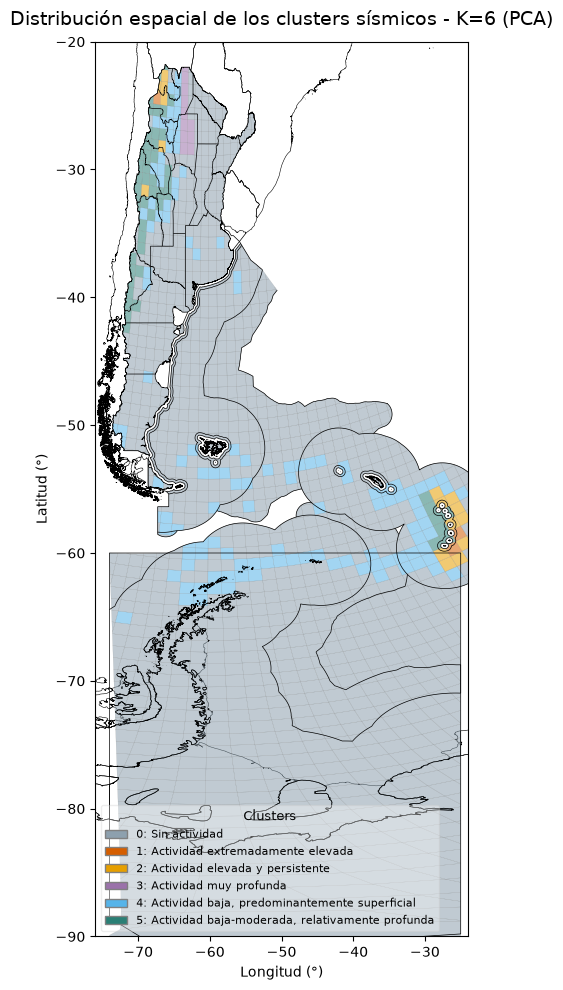

In [71]:
# ============================================================
# 8.4. VISUALIZACIÓN ESPACIAL DE LOS CLUSTERS - K=6 PCA
# ============================================================


# Definir colores para cada cluster normalizado
colores_k6 = [
    "#8DA0AE",  # Cluster 0: Sin actividad
    "#D55E00",  # Cluster 1: Actividad extremadamente elevada
    "#E69F00",  # Cluster 2: Actividad elevada y persistente
    "#9B72AA",  # Cluster 3: Actividad muy profunda
    "#56B4E9",  # Cluster 4: Actividad baja, predominantemente superficial
    "#2A7F75"   # Cluster 5: Actividad baja-moderada, relativamente profunda
]

cmap_k6 = ListedColormap(colores_k6)

# Crear figura
fig, ax = plt.subplots(figsize=(8, 10))

# Mapa de Sudamérica
ign_sudam.to_crs("EPSG:4326").plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.4
)

# Grilla coloreada según cluster
grilla_clusters_k6.to_crs("EPSG:4326").plot(
    column="cluster_normalizado",
    categorical=True,
    cmap=cmap_k6,
    ax=ax,
    edgecolor="gray",
    linewidth=0.15,
    alpha=0.55
)

# Límites de Argentina, incluida la silueta antártica
ign_arg.to_crs("EPSG:4326").plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.5
)

# Leyenda personalizada
etiquetas_k6 = [
    "0: Sin actividad",
    "1: Actividad extremadamente elevada",
    "2: Actividad elevada y persistente",
    "3: Actividad muy profunda",
    "4: Actividad baja, predominantemente superficial",
    "5: Actividad baja-moderada, relativamente profunda"
]

elementos_leyenda = [
    Patch(
        facecolor=colores_k6[i],
        edgecolor="gray",
        label=etiquetas_k6[i]
    )
    for i in range(6)
]

ax.legend(
    handles=elementos_leyenda,
    title="Clusters",
    loc="lower left",
    fontsize=8,
    title_fontsize=9,
    frameon=True,
    framealpha=0.35
)

# Configuración del mapa
ax.set_xlim(-76, -24)
ax.set_ylim(-90, -20)

ax.set_xlabel("Longitud (°)")
ax.set_ylabel("Latitud (°)")

ax.set_title(
    "Distribución espacial de los clusters sísmicos - K=6 (PCA)",
    fontsize=14,
    pad=12
)

plt.tight_layout()
plt.show()

_La distribución espacial permite complementar la caracterización estadística de los clusters y observar cómo se organizan geográficamente los distintos patrones de actividad sísmica. Mientras que el modelo K-Means sobre las variables originales ofrece una clasificación general más compacta, el modelo basado en PCA permite distinguir con mayor detalle algunos grupos de actividad baja, diferenciando zonas superficiales de otras con mayor profundidad media. De esta manera, ambas representaciones aportan perspectivas complementarias para analizar la distribución de la actividad sísmica en el área de estudio._

### 9. Episodio de agosto de 2021 e influencia en los resultados

In [60]:

# ============================================================
# 9.1. IDENTIFICACIÓN DE EVENTOS DE AGOSTO DE 2021
# ============================================================

sismos_agosto_2021 = sismos_asignados.loc[
    sismos_asignados["mes"] == pd.Period("2021-08", freq="M")
].copy()

print("Cantidad de eventos en agosto de 2021:",
      len(sismos_agosto_2021))

print("\nPrincipales lugares registrados (20 más frecuentes):")
display(
    sismos_agosto_2021["place"]
    .value_counts()
    .head(20)
)


Cantidad de eventos en agosto de 2021: 600

Principales lugares registrados (20 más frecuentes):


place
South Sandwich Islands region                          575
Scotia Sea                                               2
South Shetland Islands                                   1
4 km S of Villa Basilio Nievas, Argentina                1
114 km W of Abra Pampa, Argentina                        1
112 km W of San Antonio de los Cobres, Argentina         1
34 km NW of Villa Basilio Nievas, Argentina              1
71 km WSW of Villa General Roca, Argentina               1
96 km W of San Antonio de los Cobres, Argentina          1
87 km W of San Antonio de los Cobres, Argentina          1
40 km NNW of San Martín, Argentina                       1
96 km WNW of Candelaria, Argentina                       1
56 km WNW of San Antonio de los Cobres, Argentina        1
2021 South Sandwich Islands Earthquake                   1
42 km WSW of Villa Basilio Nievas, Argentina             1
89 km NE of Los Andes, Chile                             1
Jujuy, Argentina                                  

In [61]:
# ================================================================
# 9.2. CONTRIBUCIÓN DE AGOSTO DE 2021 EN LAS TRES CELDAS EXTREMAS 
#              - IDENTIFICADAS CON K=5 ORIGINAL -
# ================================================================

# Identificar las tres celdas
zonas_objetivo = celdas_extremas["zona_id"].tolist()

# Filtrar los eventos correspondientes a esas celdas
eventos_extremos = sismos_asignados[
    sismos_asignados["zona_id"].isin(zonas_objetivo)
].copy()

# Eventos totales por celda
totales = (
    eventos_extremos
    .groupby("zona_id")
    .size()
    .rename("sismos_periodo")
)

# Eventos de agosto de 2021
eventos_agosto = eventos_extremos[
    eventos_extremos["mes"] == pd.Period("2021-08", freq="M")
]

agosto = (
    eventos_agosto
    .groupby("zona_id")
    .size()
    .rename("sismos_agosto_2021")
)

# Eventos de agosto identificados como Islas Sandwich del Sur
eventos_sandwich = eventos_agosto[
    eventos_agosto["place"].str.contains(
        "South Sandwich Islands",
        case=False,
        na=False
    )
]

sandwich = (
    eventos_sandwich
    .groupby("zona_id")
    .size()
    .rename("sismos_sandwich_agosto")
)

# Construir tabla comparativa
resumen_agosto = (
    pd.DataFrame(index=zonas_objetivo)
    .join(totales)
    .join(agosto)
    .join(sandwich)
    .fillna(0)
)

resumen_agosto.index.name = "zona_id"

# Calcular porcentajes respecto del total de cada celda
resumen_agosto["porcentaje_agosto"] = (
    resumen_agosto["sismos_agosto_2021"]
    / resumen_agosto["sismos_periodo"].replace(0, np.nan) * 100
)

resumen_agosto["porcentaje_sandwich_agosto_sobre_total"] = (
    resumen_agosto["sismos_sandwich_agosto"]
    / resumen_agosto["sismos_periodo"].replace(0, np.nan) * 100
)

display(resumen_agosto.round(2))

,sismos_periodo,sismos_agosto_2021,sismos_sandwich_agosto,porcentaje_agosto,porcentaje_sandwich_agosto_sobre_total
zona_id,,,,,
Z00093,793,6,0.0,0.76,0.00
Z01290,515,120,120.0,23.30,23.30
Z01272,494,147,147.0,29.76,29.76


_Las proporciones observadas muestran que agosto de 2021 tuvo una incidencia diferente en cada una de las tres celdas. La evolución mensual permite observar cómo se distribuye la actividad antes y después de ese episodio._

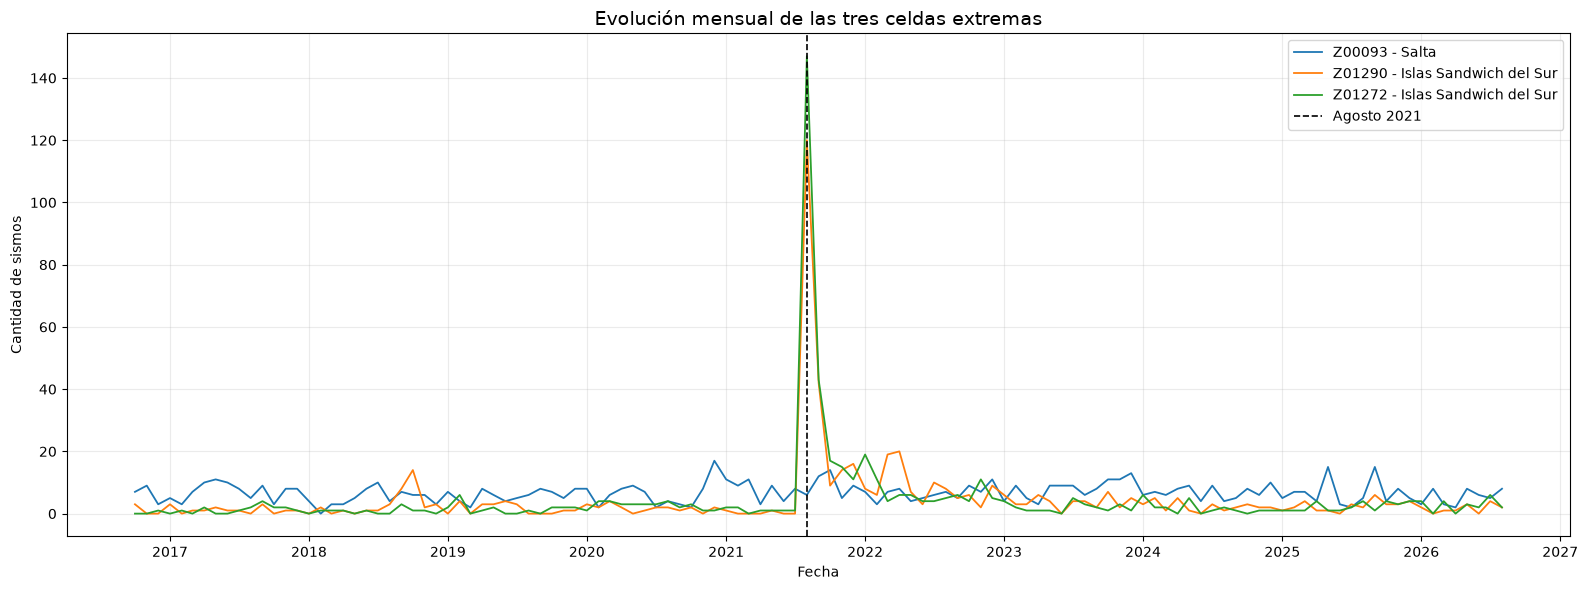

In [62]:
# ============================================================
# 9.3. EVOLUCIÓN MENSUAL DE LAS TRES CELDAS EXTREMAS
#              - IDENTIFICADAS CON K=5 ORIGINAL -
# ============================================================

# Filtrar eventos de las tres celdas
eventos_series = sismos_asignados[
    sismos_asignados["zona_id"].isin(zonas_objetivo)
].copy()

# Contar sismos por mes y celda
series_mensuales = (
    eventos_series
    .groupby(["mes", "zona_id"])
    .size()
    .unstack(fill_value=0)
)

# Completar todos los meses del período
meses_completos = pd.period_range(
    start="2016-10",
    end="2026-08",
    freq="M"
)

series_mensuales = series_mensuales.reindex(
    index=meses_completos,
    columns=zonas_objetivo,
    fill_value=0
)

# Graficar
fig, ax = plt.subplots(figsize=(16, 6))

nombres_celdas = {
    "Z00093": "Z00093 - Salta",
    "Z01290": "Z01290 - Islas Sandwich del Sur",
    "Z01272": "Z01272 - Islas Sandwich del Sur"
}

for zona_id in zonas_objetivo:

    ax.plot(
        series_mensuales.index.to_timestamp(),
        series_mensuales[zona_id],
        label=nombres_celdas.get(zona_id, zona_id),
        linewidth=1.3
    )

# Marcar agosto de 2021
ax.axvline(
    pd.Timestamp("2021-08-01"),
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Agosto 2021"
)

ax.set_title(
    "Evolución mensual de las tres celdas extremas",
    fontsize=14
)

ax.set_xlabel("Fecha")
ax.set_ylabel("Cantidad de sismos")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

##### Interpretación de la influencia del episodio de agosto de 2021

El análisis de las tres celdas extremas identificadas en la solución original K=5 permite observar diferencias en la distribución temporal de los eventos sísmicos.

Las celdas Z01290 y Z01272, ubicadas en las Islas Sandwich del Sur, presentan una concentración importante de su actividad durante agosto de 2021. En ese mes registraron 120 y 147 eventos, respectivamente, lo que representa aproximadamente el 23,3 % y el 29,7 % de sus registros totales durante el período estudiado.

En cambio, la celda Z00093, ubicada en la provincia de Salta, presenta un comportamiento diferente: sus 793 eventos se distribuyen a lo largo de 118 meses activos y solamente 6 corresponden a agosto de 2021 (0,76 % del total). Esto evidencia una actividad más sostenida en el tiempo, sin una concentración comparable a la observada en las celdas de las Islas Sandwich del Sur.

Estas diferencias ayudan a interpretar la separación de perfiles observada en los modelos de clustering. Mientras que las celdas de las Islas Sandwich del Sur están fuertemente influenciadas por el episodio de 2021 y su actividad posterior, la celda de Salta presenta un patrón de actividad más persistente.

En consecuencia, el episodio de agosto de 2021 constituye un factor relevante para interpretar los perfiles de algunas zonas, aunque no explica por sí solo la distribución espacial de la actividad sísmica ni determina la conformación de todos los clusters.

### 10. Conclusiones

El análisis no supervisado permitió identificar distintos patrones de actividad sísmica en Argentina a partir de la distribución espacial de los eventos registrados entre octubre de 2016 y agosto de 2026. Mediante la construcción de una grilla de 100 km y la caracterización de cada celda según la frecuencia, persistencia, magnitud y profundidad de los sismos, fue posible reconocer grupos con comportamientos diferenciados sin establecer previamente categorías.

La comparación entre K-Means aplicado sobre las variables originales estandarizadas y K-Means sobre componentes principales permitió analizar distintas formas de representar estos patrones. El modelo de cuatro clusters sobre las variables originales se seleccionó como clasificación general por su compacidad, interpretabilidad y mayor estabilidad frente a la selección de submuestras. Esta clasificación distingue zonas sin actividad registrada, regiones de actividad elevada y sostenida, sectores con actividad poco frecuente y profunda, y áreas de baja actividad.

Por otra parte, el modelo de seis clusters sobre PCA permitió profundizar la caracterización de las zonas con actividad reducida. En particular, diferenció sectores de baja actividad predominantemente superficial de otros con actividad baja a moderada y mayor profundidad media. Esta mayor capacidad de diferenciación aporta información adicional, aunque también presenta una mayor sensibilidad frente a las submuestras, por lo que resulta conveniente interpretarlo como un complemento del modelo principal y no como una clasificación necesariamente superior.

La representación espacial permitió relacionar los perfiles estadísticos con su distribución geográfica, mientras que el análisis del episodio de agosto de 2021 mostró que algunos de los valores extremos identificados están fuertemente asociados a la actividad concentrada en la región de las Islas Sandwich del Sur. Esto evidencia la importancia de considerar la distribución temporal y la ubicación de los eventos al interpretar los grupos, ya que una cantidad elevada de sismos acumulados no necesariamente representa una actividad persistente durante todo el período. En contraste, otras zonas presentan una actividad más distribuida en el tiempo.

En conjunto, los resultados muestran que el análisis no supervisado constituye una herramienta útil para explorar y caracterizar patrones espaciales de actividad sísmica, identificar regiones con comportamientos similares y reconocer diferencias en su frecuencia, persistencia, magnitud y profundidad. Sin embargo, las agrupaciones dependen de las variables seleccionadas, la resolución espacial de la grilla y el período analizado. Además, la elevada proporción de celdas sin actividad registrada influye en las métricas globales de evaluación y debe tenerse en cuenta al interpretar la estabilidad de los modelos.

Su principal aporte es ofrecer una representación exploratoria y comparativa de la distribución espacial de la actividad sísmica, que puede servir como punto de partida para análisis posteriores.